# 04. 로보틱스를 위한 비볼록 수치 최적화 (Nonconvex Optimization)

로봇의 역기구학(IK), 상태 추정(State Estimation), 궤적 최적화(Trajectory Optimization), 모델 예측 제어(MPC)는 모두 결국 **비선형·비볼록 최적화(Nonconvex Optimization)** 문제를 푸는 과정입니다.
이 노트북에서는 로보틱스 제어기와 솔버의 핵심 엔진이 되는 수치 최적화 기법들을 직접 구현하고 시각적으로 비교합니다.

### 학습 목표
1. **무제약 비볼록 최적화**: 경사하강법(Gradient Descent), 뉴턴 방법(Newton's Method), 그리고 **레벤버그-마쿼트(Levenberg-Marquardt) 정규화** 이해하기
2. **가우스-뉴턴(Gauss-Newton) 근사법**: 비선형 최소제곱법(Nonlinear Least Squares) 구조를 활용해 1차 미분(자코비안)만으로 2차 수렴 속도 얻기 & `mujoco.minimize.least_squares` 활용하기
3. **제약 조건부 최적화(Constrained Optimization)**:
   - **페널티 방법 (Penalty Method)**
   - **원시-쌍대 방법 (Primal-Dual Method / KKT 뉴턴-랩슨)**
   - **증강 라그랑지안 방법 (Augmented Lagrangian Method, ALM)**

---
**참고 자료:**
- Google DeepMind MuJoCo `mujoco.minimize` 튜토리얼: [google-deepmind/mujoco](https://github.com/google-deepmind/mujoco)
- Lieven Vandenberghe 교수(UCLA) 비선형 최소제곱법 강의 노트: [UCLA EE133B Notes](https://www.seas.ucla.edu/~vandenbe/133B/lectures/nllseq.pdf)
- Stanford CME 338 제약 조건부 최적화 강의 노트: [Augmented Lagrangian (BCL) Notes](https://stanford.edu/class/cme338/notes/notes11-BCL.pdf)

In [1]:
import mujoco.minimize
import numpy as np
import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt
import matplotlib.patches
import matplotlib.lines

# Windows 환경 초기화 (한글 폰트 및 프로젝트 경로 설정)
from utils.notebook_setup import init_notebook
init_notebook()

## 1. 비볼록 최적화를 위한 뉴턴 방법과 레벤버그-마쿼트(Levenberg-Marquardt) 정규화

다음과 같은 무제약 비볼록 최적화(unconstrained nonconvex optimization) 문제를 생각해 봅시다:
$$
\begin{align}
\underset{x}{\text{minimize}} \quad &f(x) \nonumber
\end{align}
$$

목적 함수 $f(x)$가 강볼록(strongly convex) 함수라면, 매 스텝마다 **뉴턴 스텝(Newton step)**을 반복 적용하여 빠르게 최적해를 찾을 수 있습니다:
$$x_{k+1} = x_k - H_k^{-1} g_k$$
여기서 $g_k = \nabla f(x_k)$는 그라디언트(Gradient), $H_k = \nabla^2 f(x_k)$는 헤시안(Hessian) 행렬입니다.

뉴턴 스텝은 현재 위치 $x_k$ 근방에서 목적 함수 $f(x)$를 2차 테일러 전개(quadratic approximation)한 근사 함수 $\hat{f}(x)$의 최솟값을 찾는 것과 같습니다:
$$x_{k+1} = \underset{x}{\text{argmin}} \ \hat{f}(x) \approx f(x_k) + g_k^T (x - x_k) + \frac{1}{2}(x - x_k)^T H_k (x - x_k)$$

하지만 **비볼록(nonconvex)** 함수에서는 헤시안 $H_k$가 양의 정부호(Positive Definite)가 아닐 수 있습니다(고유값이 0이거나 음수일 수 있음). 이 경우 $x_{k+1} = x_k - H_k^{-1} g_k$는 최솟값이 아니라 안장점(saddle point)이나 최댓값 방향으로 향할 위험이 있습니다.

이를 해결하기 위해 **레벤버그-마쿼트 정규화(Levenberg-Marquardt regularization, 또는 Damped Newton)**를 도입합니다:
$$x_{k+1} = \underset{x}{\text{argmin}} \ \hat{f}(x) + \frac{\mu}{2} \|x - x_k\|_2^2$$
이에 따른 업데이트 수식은 다음과 같습니다:
$$x_{k+1} = x_k - (H_k + \mu I)^{-1} g_k$$

정규화 파라미터 $\mu > 0$는 다음 스텝이 현재 위치 $x_k$에서 너무 멀리 벗어나지 않도록 신뢰 영역(Trust Region) 역할을 하며, $\mu$가 충분히 크면 $(H_k + \mu I)$가 항상 양의 정부호(Symmetric Positive Definite, SPD)가 되어 안정적인 하강 방향을 보장합니다.

## 2. 가우스-뉴턴(Gauss-Newton) 근사법

2차 미분인 헤시안 행렬 $H$를 매번 정확히 계산하는 것은 계산량이 매우 큽니다. 하지만 로보틱스의 많은 문제들(역기구학, 센서 융합, 궤적 추종 등)은 오차 벡터(잔차, residual) $r(x): \mathbb{R}^n \rightarrow \mathbb{R}^m$의 제곱합을 최소화하는 **비선형 최소제곱법(Nonlinear Least Squares)** 형태를 가집니다:
$$f(x) = \frac{1}{2} r(x)^T r(x) = \frac{1}{2} \|r(x)\|_2^2$$

잔차의 자코비안 행렬을 $J = \nabla r(x) \in \mathbb{R}^{m \times n}$이라 하면, 그라디언트 $g$와 헤시안 $H$는 다음과 같이 표현됩니다:
$$
\begin{align}
g &= J^T r \nonumber \\
H &= J^T J + \nabla J \cdot r \nonumber
\end{align}
$$

여기서 두 번째 항($\nabla J \cdot r$)을 생략하고 헤시안을 $H \approx H_{GN} = J^T J$로 근사하는 기법을 **가우스-뉴턴(Gauss-Newton) 근사법**이라고 합니다. 이 근사법은 두 가지 강력한 장점을 가집니다:
1. 근사 헤시안 $H_{GN} = J^T J$는 행렬의 제곱 형태이므로 항상 **양의 준정부호(Positive Semi-Definite)**입니다. 따라서 임의의 $\mu > 0$에 대해 레벤버그-마쿼트 행렬 $H_{GN} + \mu I = J^T J + \mu I$는 **항상 대칭 양의 정부호(SPD)**임이 보장됩니다!
2. $H_{GN}$을 구하기 위해 2차 미분을 계산할 필요 없이 **1차 미분인 자코비안 $J$만 있으면 됩니다.** 즉, 1차 미분 비용만으로 2차 최적화에 준하는 빠른 수렴 속도를 얻을 수 있습니다.

## 3. 벤치마크 함수 실습: 경사하강법 vs 완전 뉴턴법 vs 가우스-뉴턴법

2차원 등고선(contour) 그래프 위에 최적화 알고리즘의 수렴 궤적(trace)과 제약 조건들을 시각화해 주는 헬퍼 함수 `plot_2D`를 먼저 정의합니다:

In [2]:
def plot_2D(residual, name, plot_range, true_minimum=None, trace=None, bounds=None, equality_constraints=None):
    """2차원 최소제곱 목적 함수의 등고선과 최적화 수렴 궤적을 시각화합니다."""
    n = 400
    x_range, y_range = plot_range
    x_grid = np.linspace(x_range[0], x_range[1], n)
    y_grid = np.linspace(y_range[0], y_range[1], n)
    X, Y = np.meshgrid(x_grid, y_grid)

    R = residual(np.stack((X, Y)))
    Z = 0.5 * np.sum(R**2, axis=0)

    fig = plt.figure(figsize=(8, 8))
    cntr_levels = np.linspace(0, np.log1p(Z.max()), 30)
    plt.contour(X, Y, np.log1p(Z), cntr_levels, linewidths=0.5)
    plt.title(name)
    plt.xlabel('x')
    plt.ylabel('y')

    # 박스 제약 조건(Bounds) 그리기
    hbounds = None
    if bounds is not None:
        lower, upper = bounds
        width = upper[0] - lower[0]
        height = upper[1] - lower[1]
        rect = matplotlib.patches.Rectangle(lower, width, height, edgecolor='blue', facecolor='none',
                        fill=False, lw=1)
        hbounds = fig.axes[0].add_patch(rect)

    # 등식 제약 조건(Equality constraints: g(x) = 0) 곡선 그리기
    hefc = None
    if equality_constraints is not None:
        E = equality_constraints(np.stack((X, Y))).squeeze()
        plt.contour(X, Y, E, [0], linewidths=2.0, colors='orange')
        hefc = matplotlib.lines.Line2D([], [], color='orange', linewidth=2.0)

    # 시작점, 이동 궤적, 최종 수렴점 마커 스타일
    point_spec = {'markersize': 10, 'markeredgewidth': 2, 'fillstyle': 'none',
                    'marker': 'o', 'linestyle': 'none'}
    curve_spec = {'marker': 'o', 'markersize': 2, 'linewidth': 1.5,
                    'color': 'red', 'alpha': 0.5}
    final_spec = {'marker': 'o', 'markersize': 5, 'color': 'green',
                    'linestyle': 'none'}

    # 전역 최적점(Global Minimum) 표시
    hmin = None
    if true_minimum is not None:
        hmin = plt.plot(true_minimum[0], true_minimum[1], color='pink', **point_spec)

    def add_curve(t):
        x0 = plt.plot(t[0, 0], t[0, 1], color='grey', **point_spec)
        traj = plt.plot(t[:, 0], t[:, 1], **curve_spec)
        final = plt.plot(t[-1, 0], t[-1, 1], **final_spec)
        return x0, traj, final

    handles = []
    labels = []
    if trace is not None:
        if isinstance(trace, list):
            for t in trace:
                x0, traj, final = add_curve(t)
        else:
            x0, traj, final = add_curve(trace)

        handles = [x0[0], traj[0], final[0]]
        labels = ['초기점 ($x_0$)', '최적화 궤적 (trace)', '수렴 해 (solution)']
   
    if hmin is not None:
        handles.append(hmin[0])
        labels.append('전역 최적점 (true minimum)')
    if hbounds is not None:
        handles.append(hbounds)
        labels.append('박스 제약 (box bounds)')
    if hefc is not None:
        handles.append(hefc)
        labels.append('등식 제약 ($g(x)=0$)')
    
    if len(handles) > 0:
        plt.legend(handles, labels)

    plt.show()

### 3.1 로젠브록 함수 (Rosenbrock Function)
첫 번째 벤치마크 함수는 좁고 휘어진 바나나 모양의 골짜기를 가져 최적화 알고리즘 테스트에 널리 쓰이는 **[로젠브록 함수(Rosenbrock function)](https://en.wikipedia.org/wiki/Rosenbrock_function)**입니다:
$$f(x,y) = \frac{1}{2}r(x,y)^T r(x,y), \quad r(x,y)=\begin{pmatrix} 1-x \\ 10(y-x^2) \end{pmatrix}$$
전역 최솟값은 $(x^*, y^*) = (1, 1)$이며 이때 $f(1, 1) = 0$입니다.

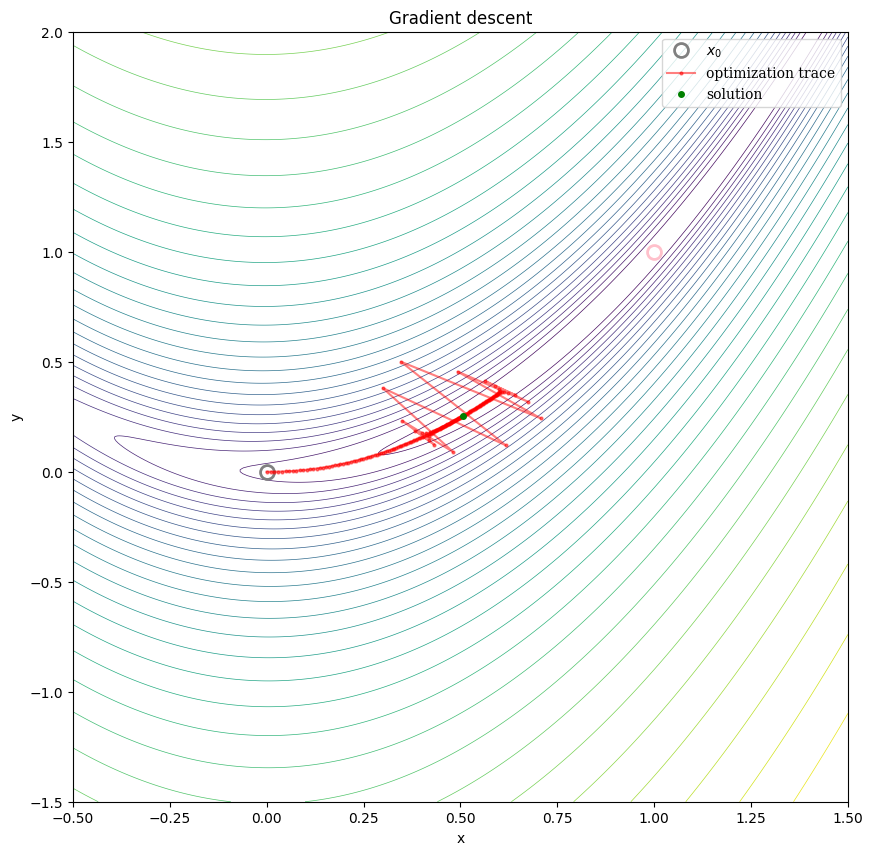

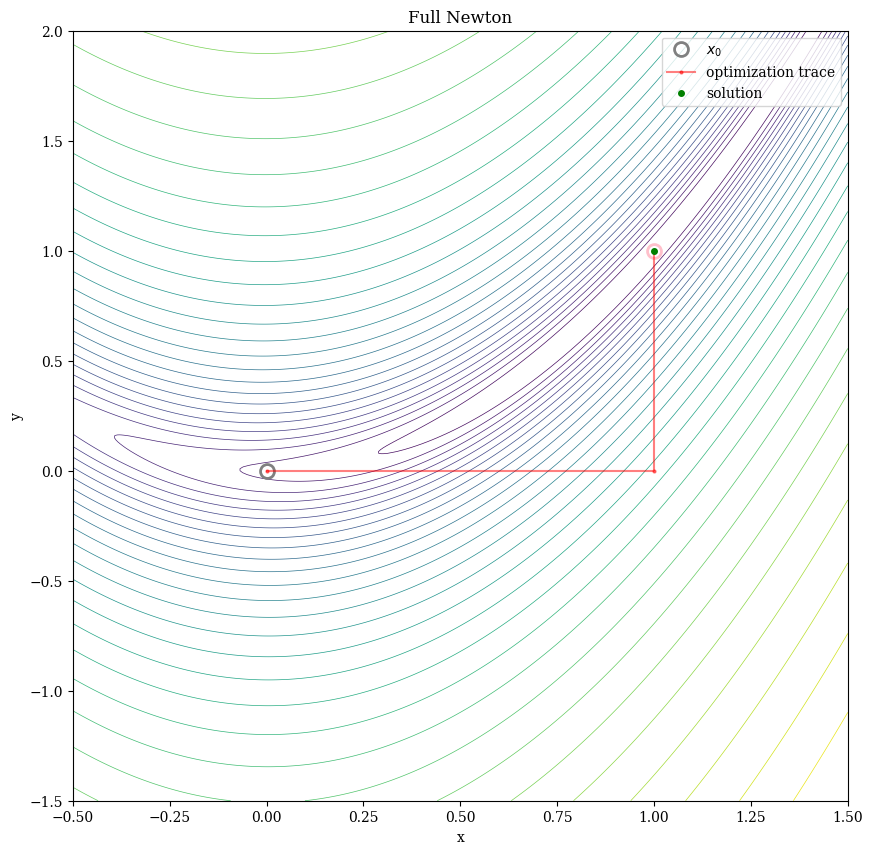

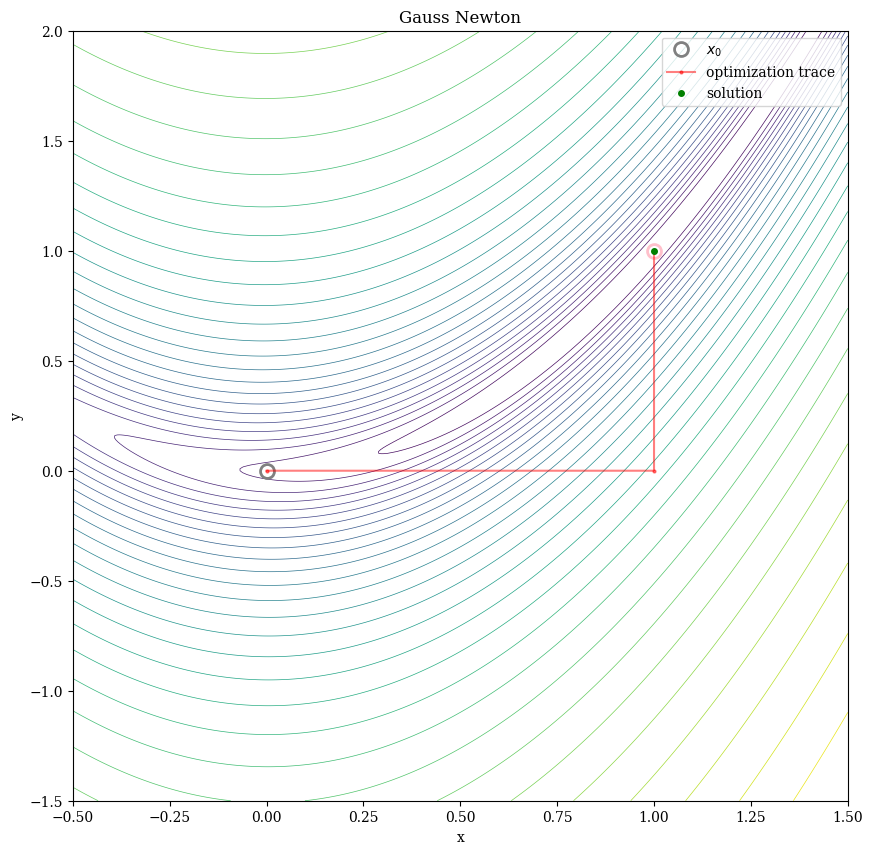

In [3]:
def rosenbrock_jax(x):
    return jnp.array([1 - x[0], 10 * (x[1] - x[0] ** 2)])

plot_range = (np.array((-0.5, 1.5)), np.array((-1.5, 2.)))
minimum = (1, 1)

def gradient_descent(residual_fn, step_size, x0, max_it=int(200)):
    """1차 경사하강법 (Gradient Descent)"""
    jac = jax.jacobian(residual_fn)
    @jax.jit
    def grad(x):
        return jac(x).T @ residual_fn(x)
    xs = [x0]
    for i in range(max_it):
        xs.append(xs[-1] - step_size * grad(xs[-1]))
    return np.array(xs)

def full_newton(residual_fn, step_size, x0, mu=0, max_it=int(200)):
    """정확한 헤시안을 사용하는 완전 뉴턴법 (Full Newton with LM regularization)"""
    def f(x):
        return 0.5 * jnp.sum(residual_fn(x)**2)
    grad = jax.jit(jax.grad(f))
    hess = jax.jit(jax.hessian(f))
    xs = [x0]
    for i in range(max_it):
        xs.append(xs[-1] - step_size * jax.numpy.linalg.inv(hess(xs[-1]) + mu * jnp.diag(jnp.ones_like(xs[-1]))) @ grad(xs[-1]))
    return np.array(xs)

def gauss_newton(residual_fn, step_size, x0, mu=0, max_it=int(200)):
    """자코비안만으로 헤시안을 근사하는 가우스-뉴턴법 (Gauss-Newton with LM regularization)"""
    jac = jax.jacobian(residual_fn)

    @jax.jit
    def grad(x):
        return jac(x).T @ residual_fn(x)
    @jax.jit
    def hess(x):
        return jac(x).T @ jac(x)
    xs = [x0]
    for i in range(max_it):
        xs.append(xs[-1] - step_size * jax.numpy.linalg.inv(hess(xs[-1]) + mu * jnp.diag(jnp.ones_like(xs[-1]))) @ grad(xs[-1]))
    return np.array(xs)

x0 = np.array([0.0, 0.0])

plot_2D(rosenbrock_jax, 'Rosenbrock - 경사하강법 (Gradient Descent, 200 iter)', plot_range, minimum, trace=gradient_descent(rosenbrock_jax, step_size=0.01, x0=x0))
plot_2D(rosenbrock_jax, 'Rosenbrock - 완전 뉴턴법 (Full Newton, 50 iter)', plot_range, minimum, trace=full_newton(rosenbrock_jax, step_size=1, mu=0, x0=x0, max_it=50))
plot_2D(rosenbrock_jax, 'Rosenbrock - 가우스-뉴턴법 (Gauss-Newton, 50 iter)', plot_range, minimum, trace=gauss_newton(rosenbrock_jax, step_size=1, mu=0, x0=x0, max_it=50))

### 3.2 빌 함수 (Beale Function)
조금 더 복잡한 비볼록 지형을 가진 **[빌 함수(Beale function)](https://en.wikipedia.org/wiki/Test_functions_for_optimization#Test_functions_for_single-objective_optimization)**를 살펴보겠습니다:
$$f(x,y) = \frac{1}{2} r(x,y)^T r(x,y), \quad r(x,y)=\begin{pmatrix} 1.5 - x + xy \\ 2.25 - x + xy^2 \\ 2.625 - x + xy^3 \end{pmatrix}$$
전역 최솟값은 $(x^*, y^*) = (3, 0.5)$입니다.
시작점을 $x_0 = (-3, -3)$으로 두면 비볼록성이 강한 영역을 지나가야 하므로 정규화 파라미터 $\mu = 5$의 역할이 매우 중요해집니다:

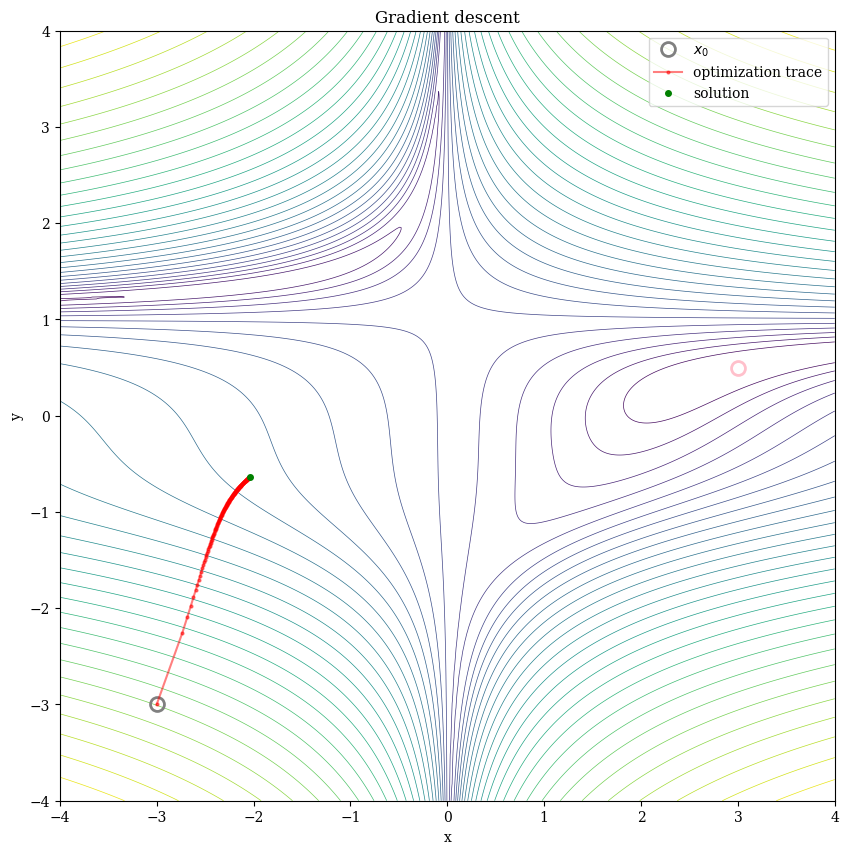

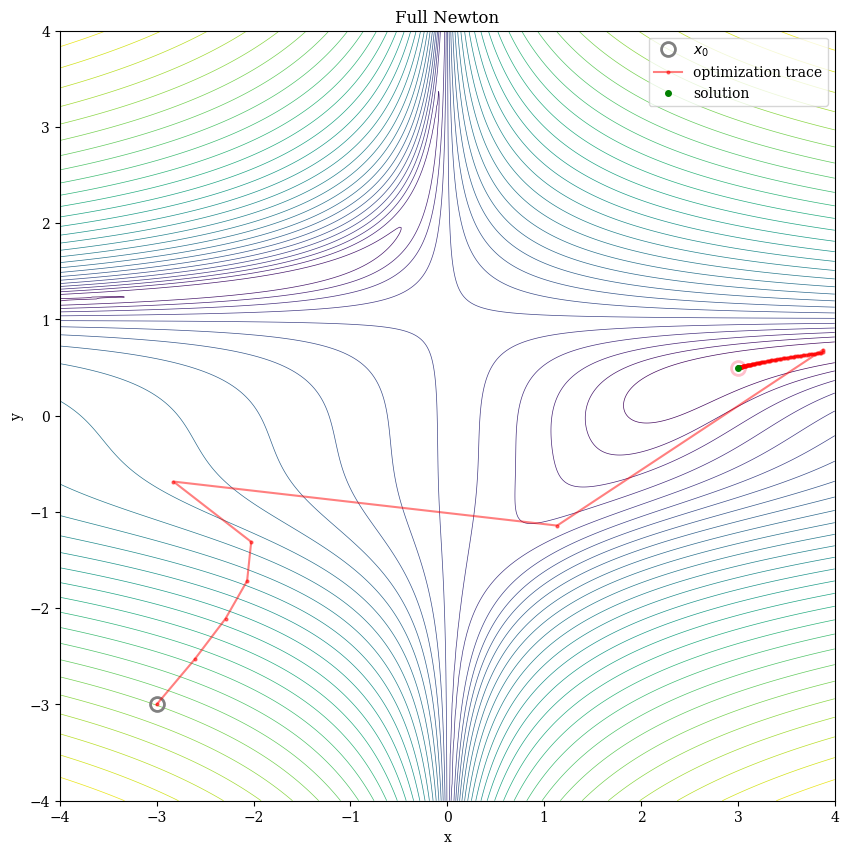

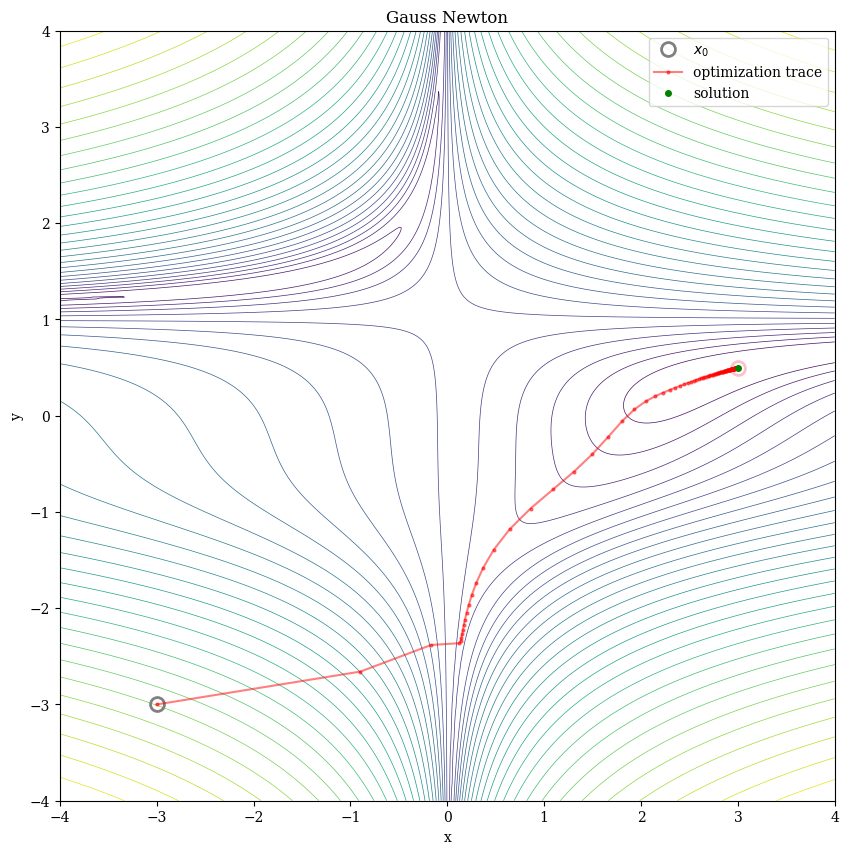

In [4]:
def beale_jax(x):
    return jnp.array((1.5 - x[0] + x[0]*x[1],
                      2.25 - x[0] + x[0]*x[1]*x[1],
                      2.625 - x[0] + x[0]*x[1]*x[1]*x[1]))

plot_range = (np.array((-4., 4.)), np.array((-4., 4.)))
minimum = (3., 0.5)

x0 = np.array((-3.0, -3.0))
plot_2D(beale_jax, 'Beale - 경사하강법 (Gradient Descent)', plot_range, minimum, trace=gradient_descent(beale_jax, step_size=0.0001, x0=x0))
plot_2D(beale_jax, 'Beale - 완전 뉴턴법 (Full Newton, mu=5)', plot_range, minimum, trace=full_newton(beale_jax, step_size=1, mu=5, x0=x0))
plot_2D(beale_jax, 'Beale - 가우스-뉴턴법 (Gauss-Newton, mu=5)', plot_range, minimum, trace=gauss_newton(beale_jax, step_size=1, mu=5, x0=x0))

iter: 0    y: 4080       log10mu: -inf  ratio: 1        dx: 2.9      reduction: 4.1e+03
iter: 1    y: 11.2       log10mu: -inf  ratio: 0.6      dx: 2.3      reduction: 3.8    
iter: 2    y: 7.371      log10mu: -0.9  ratio: 0.047    dx: 1.6      reduction: 0.26   
iter: 3    y: 7.109      log10mu: -0.8  ratio: 1        dx: 0.38     reduction: 4.7    
iter: 4    y: 2.408      log10mu: -0.9  ratio: 1.4      dx: 0.51     reduction: 1.3    
iter: 5    y: 1.155      log10mu: -1.1  ratio: 1.5      dx: 0.57     reduction: 0.83   
iter: 6    y: 0.3266     log10mu: -1.5  ratio: 0.55     dx: 0.62     reduction: 0.16   
iter: 7    y: 0.1643     log10mu: -1.5  ratio: 1        dx: 0.47     reduction: 0.16   
iter: 8    y: 0.0006372  log10mu: -2.3  ratio: 0.99     dx: 0.077    reduction: 0.00063
iter: 9    y: 6.587e-06  log10mu: -3.9  ratio: 1        dx: 0.0047   reduction: 6.6e-06
iter: 10   y: 1.542e-11  log10mu: -inf  ratio: 1        dx: 6.2e-06  reduction: 1.5e-11
iter: 11   y: 8.581e-24  log10mu

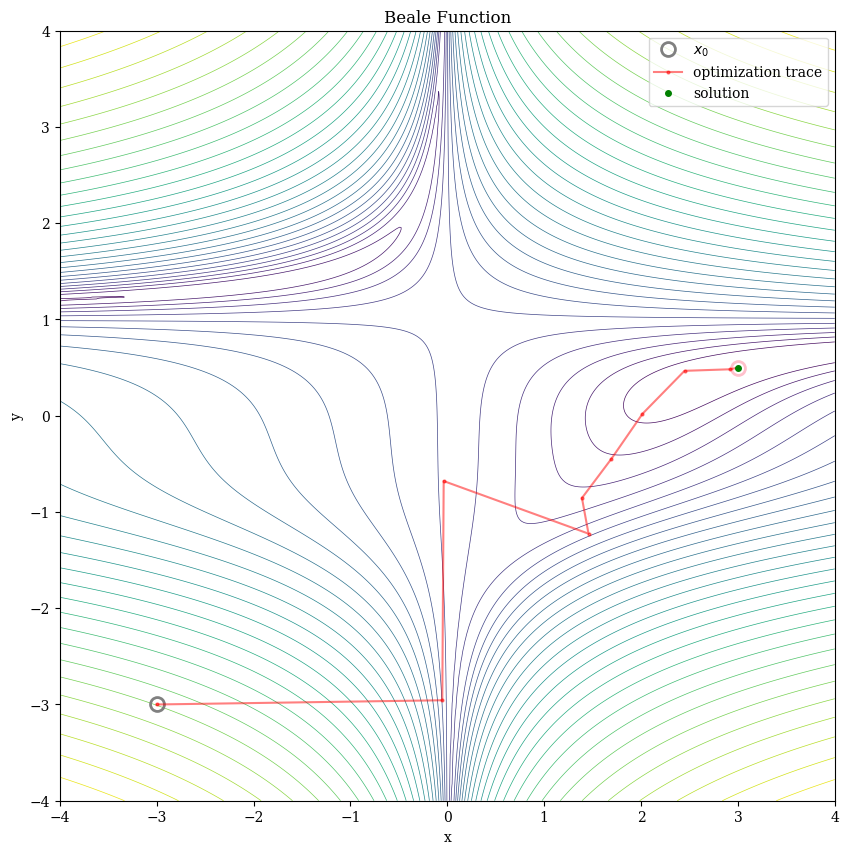

In [5]:
# MuJoCo에 내장된 비선형 최소제곱 솔버(mujoco.minimize.least_squares)를 사용해 봅니다.
# 참고: mujoco.minimize.least_squares는 잔차 함수가 배치 입력(shape: [n, batch_size])을 받아
# float64 NumPy 배열을 반환하도록 요구합니다.
def beale(x):
    return np.stack((1.5 - x[0, :] + x[0, :]*x[1, :],
                     2.25 - x[0, :] + x[0, :]*x[1, :]*x[1, :],
                     2.625 - x[0, :] + x[0, :]*x[1, :]*x[1, :]*x[1, :]))

x, bl_trace = mujoco.minimize.least_squares(x0, beale)
plot_2D(beale, 'MuJoCo 내장 솔버 (mujoco.minimize.least_squares)', plot_range, minimum, trace=np.asarray([t.candidate for t in bl_trace]))

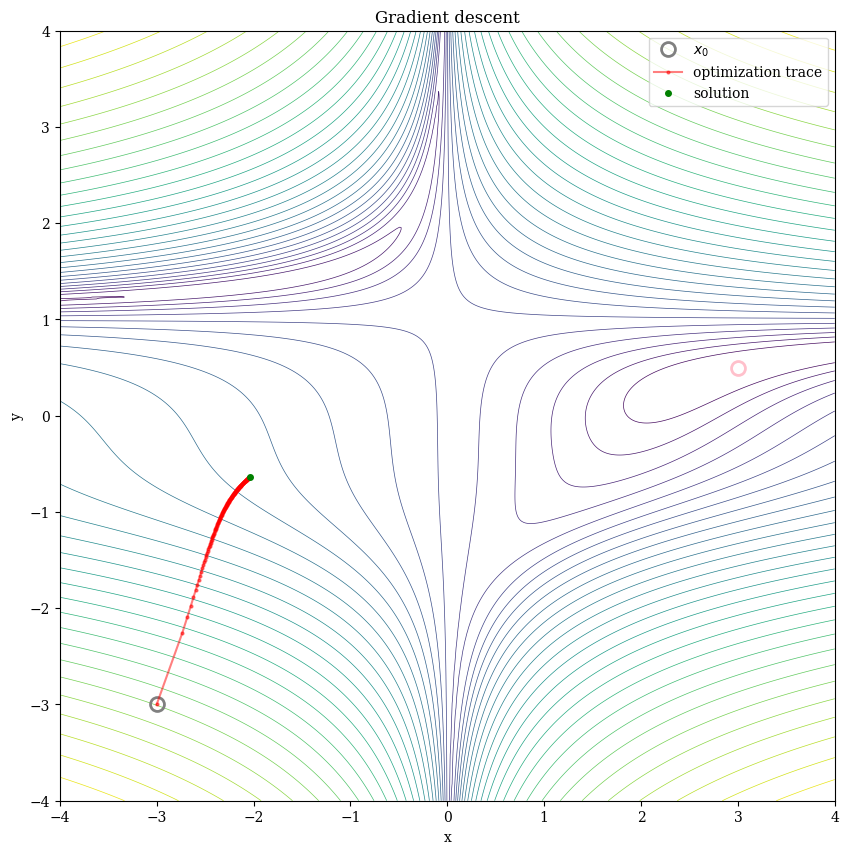

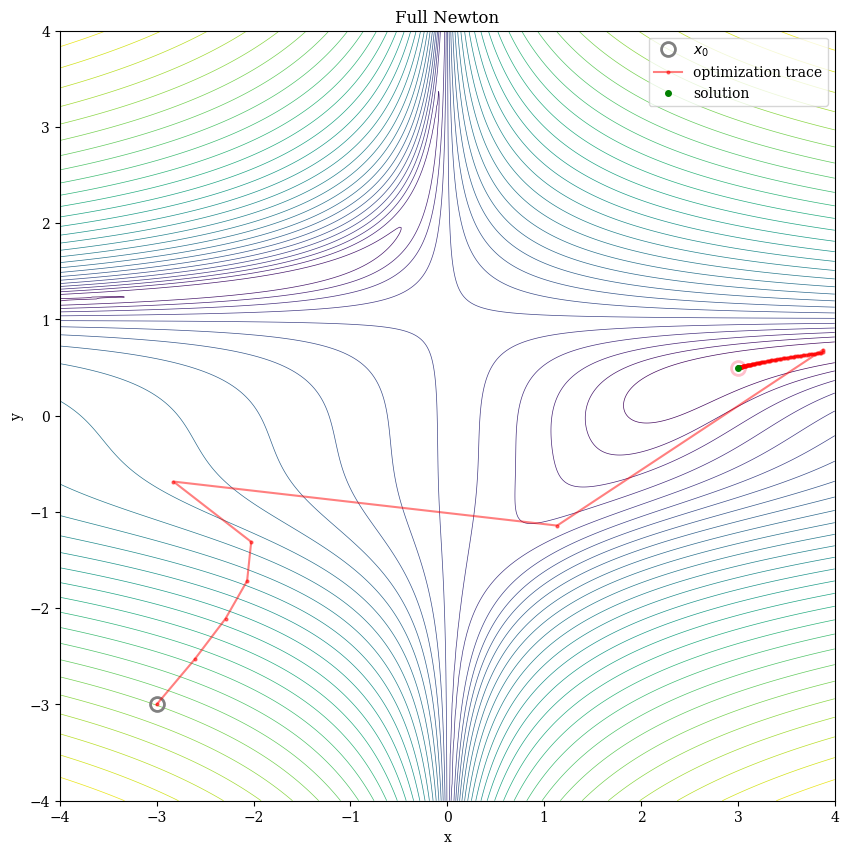

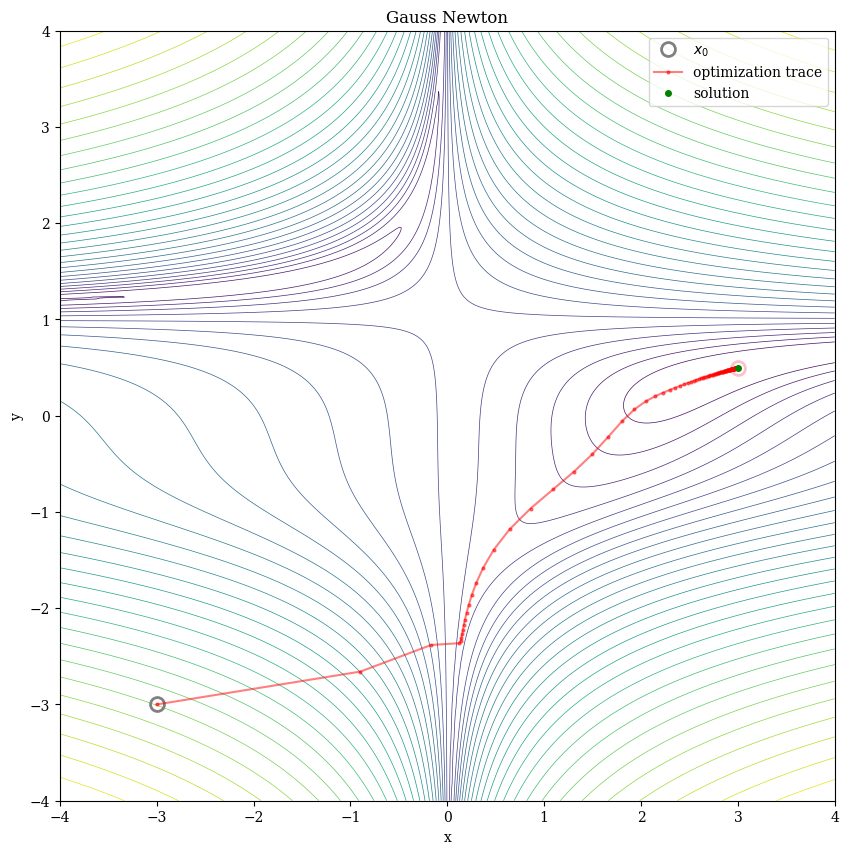

In [6]:
# 참고: MuJoCo의 least_squares 솔버는 내부적으로 적응형(adaptive) Levenberg-Marquardt 정규화와
# 유한차분 자코비안(Gauss-Newton)을 결합하여 단 몇 번의 반복만으로 전역 최적점 (3.0, 0.5)에 정확히 도달합니다!
print(f"MuJoCo least_squares 최종 수렴 해: {x.flatten()}, 총 반복 횟수: {len(bl_trace)}")

---
## 4. 등식 제약 조건부 최적화 (Equality-Constrained Optimization)

이제 로봇 제어에서 빈번히 등장하는(예: 폐루프 기구학 구속, 동역학 구속, 목표 지점 도달 제약 등) **등식 제약 조건부 최적화** 문제를 생각해 봅시다:
$$
\begin{align}
\underset{x}{\text{minimize}} \quad &f(x) = \frac{1}{2}\|r(x)\|_2^2 \nonumber \\
\text{subject to} \quad &g(x) = 0 \nonumber
\end{align}
$$

### 4.1 페널티 방법 (Penalty Method)

등식 제약 조건 $g(x) = 0$을 다루는 가장 단순한 방법은 제약 조건 위반량을 목적 함수의 **페널티(벌점) 항**으로 바꾸어 무제약 최적화 문제를 순차적으로 푸는 것입니다:
$$
\underset{x}{\text{minimize}} \quad f(x) + \frac{\rho}{2} \|g(x)\|_2^2
$$
최소제곱법 형태로는 잔차 벡터 아래에 $\sqrt{\rho} g(x)$를 이어 붙여 다음과 같이 쓸 수 있습니다:
$$
\underset{x}{\text{minimize}} \quad \frac{1}{2}\left\|\begin{bmatrix} r(x)\\ \sqrt{\rho} g(x) \end{bmatrix}\right\|_2^2
$$
페널티 가중치 $\rho$를 작은 값에서 시작해 점진적으로 크게 늘려가며($\rho \to \infty$), 이전 단계의 해를 다음 단계의 초기값(Warm-start)으로 사용합니다.

**예제 문제:** 빌 함수(Beale function)를 최소화하되, 로젠브록 함수 값이 1이 되는 주황색 타원형 등고선($g(x) = \frac{1}{2}\|r_{\text{rosenbrock}}(x)\|_2^2 - 1 = 0$) 위에 해가 존재해야 한다는 등식 제약을 부여합니다.
$\rho$가 증가함에 따라 각 서브루틴의 지형(landscape)과 해가 어떻게 변하는지 확인해 보겠습니다:

iter: 0    y: 7.103      log10mu: -inf  ratio: 0.21     dx: 1.5      reduction: 1.1    
iter: 1    y: 5.975      log10mu: -0.9  ratio: 0.13     dx: 1.3      reduction: 0.7    
iter: 2    y: 5.273      log10mu: -0.8  ratio: 0.71     dx: 0.52     reduction: 3.5    
iter: 3    y: 1.773      log10mu: -0.5  ratio: 0.34     dx: 0.86     reduction: 0.48   
iter: 4    y: 1.294      log10mu: -0.5  ratio: 0.94     dx: 0.25     reduction: 0.77   
iter: 5    y: 0.5219     log10mu: -0.6  ratio: 0.5      dx: 0.38     reduction: 0.032  
iter: 6    y: 0.4904     log10mu: -0.6  ratio: 0.63     dx: 0.078    reduction: 0.0046 
iter: 7    y: 0.4858     log10mu: -0.6  ratio: 3.7      dx: 0.014    reduction: 0.00027
iter: 8    y: 0.4855     log10mu: -0.6  ratio: 0.047    dx: 0.11     reduction: 0.00019
iter: 9    y: 0.4853     log10mu: -0.5  ratio: 0.081    dx: 0.079    reduction: 0.00019
iter: 10   y: 0.4852     log10mu:  0.5  ratio: 0.05     dx: 0.0025   reduction: 2.3e-06
iter: 11   y: 0.4852     log10mu

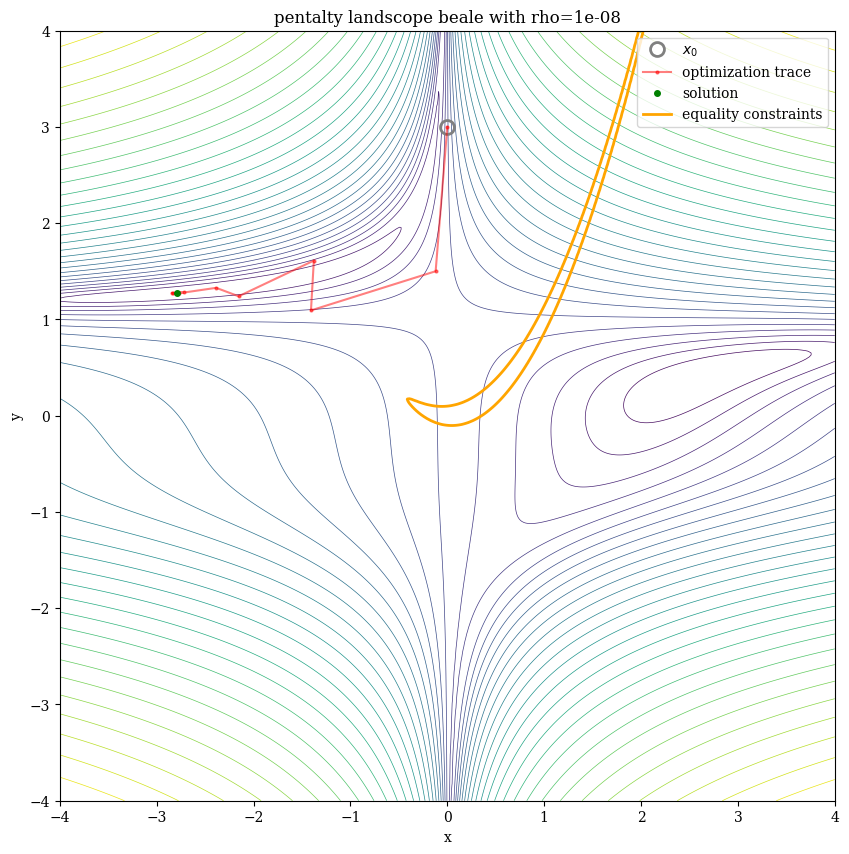

iter: 0    y: 1.277      log10mu: -inf  ratio: 0.9      dx: 0.55     reduction: 0.68   
iter: 1    y: 0.6004     log10mu: -inf  ratio: 0.52     dx: 0.35     reduction: 0.035  
iter: 2    y: 0.5654     log10mu: -1.4  ratio: 0.056    dx: 0.19     reduction: 0.0005 
iter: 3    y: 0.5649     log10mu: -1.3  ratio: 0.83     dx: 0.12     reduction: 0.0043 
iter: 4    y: 0.5606     log10mu: -0.6  ratio: 0.046    dx: 0.036    reduction: 2.7e-05
iter: 5    y: 0.5605     log10mu: -0.5  ratio: 0.63     dx: 0.018    reduction: 0.00011
iter: 6    y: 0.5604     log10mu:  4.3  ratio: 0.36     dx: 2e-06    reduction: 2.9e-08
iter: 7    y: 0.5604     log10mu:  4.5  ratio: 0.066    dx: 7.6e-07  reduction: 1.2e-09
Terminated after 7 iterations: norm(dx) < tol. y: 0.5604, Residual evals: 130
total time 24.0ms of which residual 90.2%


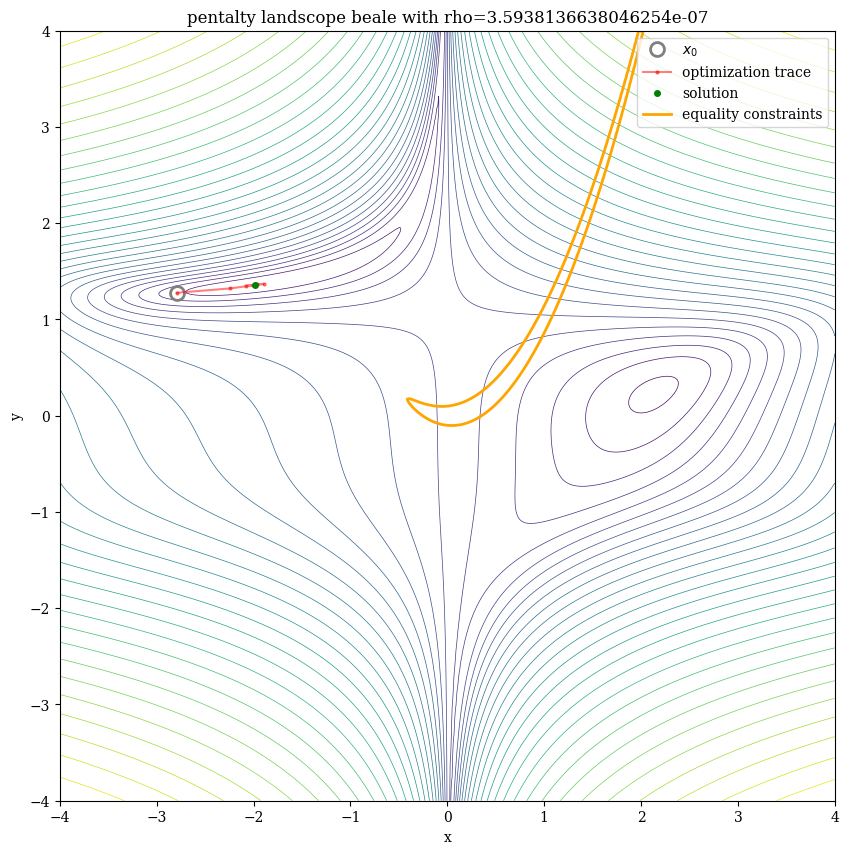

iter: 0    y: 1.262      log10mu: -inf  ratio: 0.9      dx: 0.31     reduction: 0.61   
iter: 1    y: 0.654      log10mu: -inf  ratio: 0.68     dx: 0.16     reduction: 0.03   
iter: 2    y: 0.624      log10mu: -inf  ratio: 2.4      dx: 0.014    reduction: 0.00057
iter: 3    y: 0.6235     log10mu:  1.6  ratio: 0.18     dx: 0.00019  reduction: 4.8e-07
iter: 4    y: 0.6235     log10mu:  3.2  ratio: 0.18     dx: 4.5e-06  reduction: 5.9e-09
iter: 5    y: 0.6235     log10mu:  3.3  ratio: 0.32     dx: 3.4e-05  reduction: 7.5e-07
iter: 6    y: 0.6235     log10mu:  3.3  ratio: 0.29     dx: 3.3e-05  reduction: 6.5e-07
iter: 7    y: 0.6235     log10mu:  4.1  ratio: 0.097    dx: 2.9e-06  reduction: 1e-08  
iter: 8    y: 0.6235     log10mu:  4.2  ratio: 0.11     dx: 5.3e-06  reduction: 5e-08  
iter: 9    y: 0.6235     log10mu:  4.3  ratio: 0.41     dx: 1.8e-06  reduction: 2.8e-08
iter: 10   y: 0.6235     log10mu:  4.3  ratio: 0.34     dx: 3.8e-06  reduction: 9.6e-08
iter: 11   y: 0.6235     log10mu

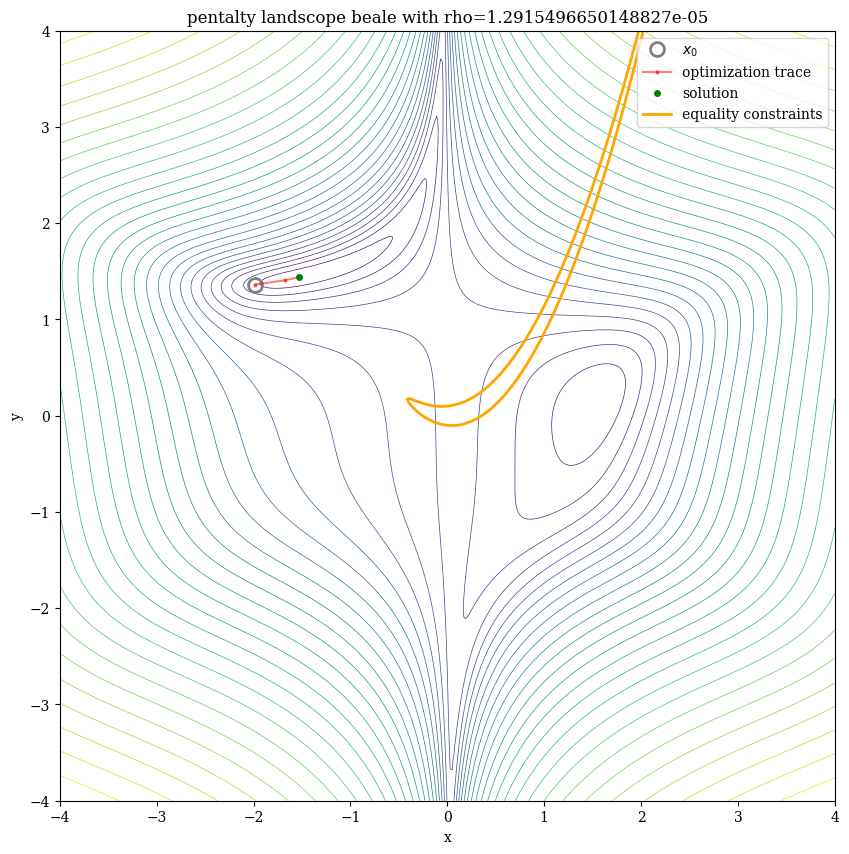

iter: 0    y: 1.06       log10mu: -inf  ratio: 0.9      dx: 0.14     reduction: 0.38   
iter: 1    y: 0.679      log10mu: -inf  ratio: 0.84     dx: 0.065    reduction: 0.017  
iter: 2    y: 0.6623     log10mu:  1.3  ratio: 0.034    dx: 0.0044   reduction: 1.4e-05
iter: 3    y: 0.6623     log10mu:  1.4  ratio: 0.21     dx: 0.0012   reduction: 8.6e-06
iter: 4    y: 0.6623     log10mu:  1.6  ratio: 0.018    dx: 0.00063  reduction: 2.9e-07
iter: 5    y: 0.6623     log10mu:  1.9  ratio: 0.012    dx: 0.00035  reduction: 1.2e-07
iter: 6    y: 0.6623     log10mu:  3.3  ratio: 0.019    dx: 1.3e-05  reduction: 6.5e-09
iter: 7    y: 0.6623     log10mu:  5.0  ratio: 0.18     dx: 4.1e-07  reduction: 3e-09  
Terminated after 7 iterations: norm(dx) < tol. y: 0.6623, Residual evals: 131
total time 26.0ms of which residual 90.2%


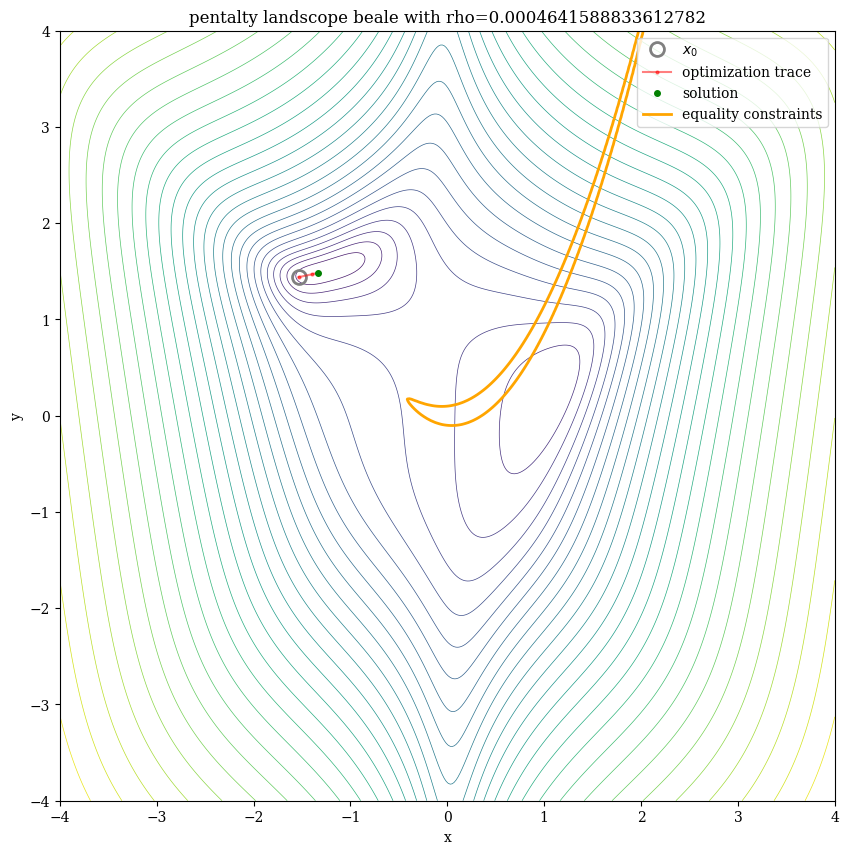

iter: 0    y: 0.9467     log10mu: -inf  ratio: 0.88     dx: 0.068    reduction: 0.24   
iter: 1    y: 0.7068     log10mu: -inf  ratio: 0.21     dx: 0.051    reduction: 0.0041 
iter: 2    y: 0.7027     log10mu:  1.0  ratio: 0.26     dx: 0.036    reduction: 0.0035 
iter: 3    y: 0.6991     log10mu:  1.0  ratio: 0.31     dx: 0.018    reduction: 0.0014 
iter: 4    y: 0.6977     log10mu:  1.0  ratio: 1.3      dx: 0.0052   reduction: 0.00037
iter: 5    y: 0.6974     log10mu:  3.6  ratio: 0.14     dx: 4.1e-06  reduction: 9.7e-09
iter: 6    y: 0.6974     log10mu:  3.7  ratio: 0.78     dx: 4.5e-06  reduction: 7.9e-08
iter: 7    y: 0.6974     log10mu:  3.6  ratio: 0.34     dx: 1.3e-05  reduction: 2.2e-07
iter: 8    y: 0.6974     log10mu:  3.6  ratio: 0.33     dx: 1.3e-05  reduction: 2.1e-07
iter: 9    y: 0.6974     log10mu:  3.6  ratio: 0.17     dx: 2e-05    reduction: 2.7e-07
iter: 10   y: 0.6974     log10mu:  3.7  ratio: 2.3      dx: 1.8e-06  reduction: 3.9e-08
iter: 11   y: 0.6974     log10mu

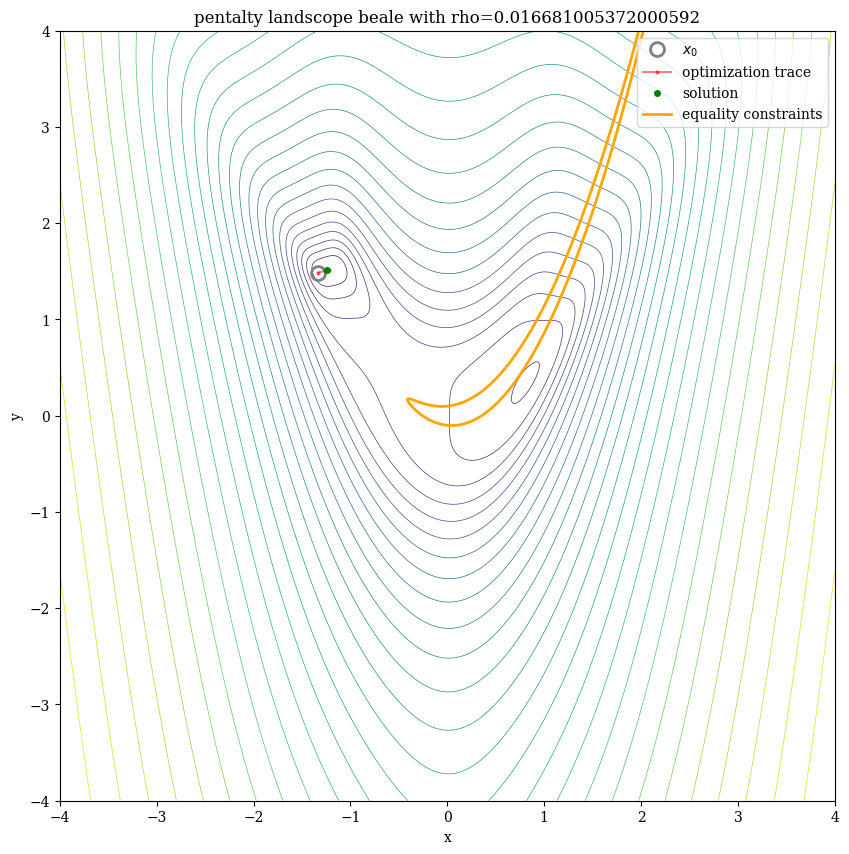

iter: 0    y: 1.394      log10mu:  2.5  ratio: 0.12     dx: 0.023    reduction: 0.022  
iter: 1    y: 1.372      log10mu:  2.6  ratio: 0.26     dx: 0.015    reduction: 0.024  
iter: 2    y: 1.348      log10mu:  2.6  ratio: 0.23     dx: 0.0078   reduction: 0.0056 
iter: 3    y: 1.342      log10mu:  2.7  ratio: 0.39     dx: 0.0036   reduction: 0.0025 
iter: 4    y: 1.34       log10mu:  2.7  ratio: 0.66     dx: 0.001    reduction: 0.00035
iter: 5    y: 1.34       log10mu:  2.7  ratio: 1        dx: 0.0005   reduction: 0.00014
iter: 6    y: 1.339      log10mu:  2.6  ratio: 1.1      dx: 0.00047  reduction: 0.00011
iter: 7    y: 1.339      log10mu:  2.4  ratio: 0.57     dx: 0.00074  reduction: 8.8e-05
iter: 8    y: 1.339      log10mu:  2.5  ratio: 0.067    dx: 0.00083  reduction: 1.5e-05
iter: 9    y: 1.339      log10mu:  2.6  ratio: 0.13     dx: 0.00087  reduction: 4.1e-05
iter: 10   y: 1.339      log10mu:  2.7  ratio: 0.49     dx: 0.00047  reduction: 5.7e-05
iter: 11   y: 1.339      log10mu

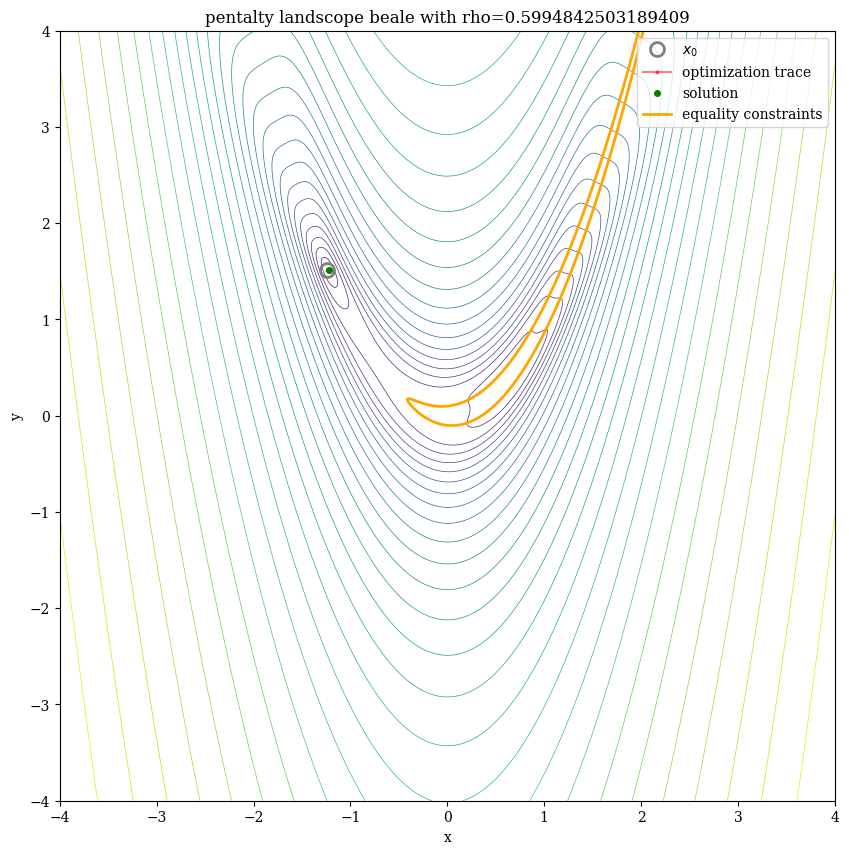

iter: 0    y: 24.24      log10mu:  3.0  ratio: 0.12     dx: 0.025    reduction: 0.075  
iter: 1    y: 24.17      log10mu:  4.1  ratio: 0.19     dx: 0.012    reduction: 0.33   
iter: 2    y: 23.84      log10mu:  4.2  ratio: 0.36     dx: 0.0064   reduction: 0.23   
iter: 3    y: 23.61      log10mu:  4.2  ratio: 0.52     dx: 0.0027   reduction: 0.06   
iter: 4    y: 23.55      log10mu:  4.2  ratio: 0.84     dx: 0.0017   reduction: 0.037  
iter: 5    y: 23.51      log10mu:  4.1  ratio: 0.97     dx: 0.0019   reduction: 0.042  
iter: 6    y: 23.47      log10mu:  3.9  ratio: 0.97     dx: 0.0029   reduction: 0.064  
iter: 7    y: 23.4       log10mu:  3.5  ratio: 0.8      dx: 0.0072   reduction: 0.13   
iter: 8    y: 23.27      log10mu:  3.9  ratio: 0.088    dx: 0.0049   reduction: 0.017  
iter: 9    y: 23.26      log10mu:  4.0  ratio: 0.096    dx: 0.0057   reduction: 0.032  
iter: 10   y: 23.22      log10mu:  4.1  ratio: 0.26     dx: 0.005    reduction: 0.081  
iter: 11   y: 23.14      log10mu

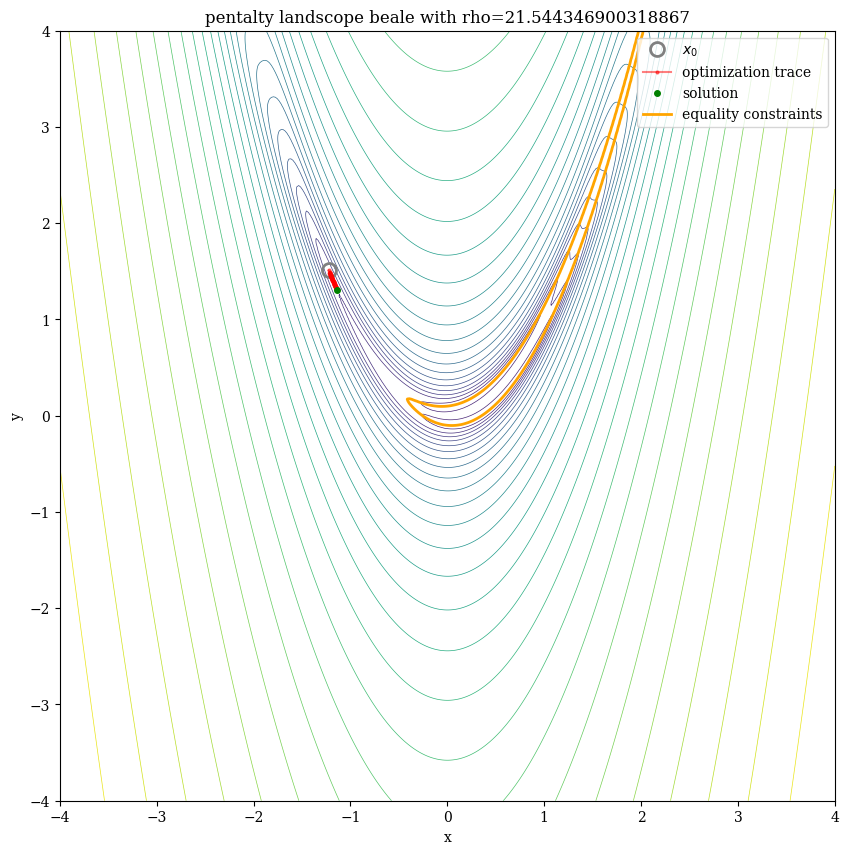

iter: 0    y: 652.2      log10mu:  4.8  ratio: 0.032    dx: 0.015    reduction: 0.44   
iter: 1    y: 651.8      log10mu:  5.5  ratio: 0.11     dx: 0.012    reduction: 4.7    
iter: 2    y: 647        log10mu:  5.6  ratio: 0.29     dx: 0.0082   reduction: 7.9    
iter: 3    y: 639.1      log10mu:  5.6  ratio: 0.4      dx: 0.0046   reduction: 3.4    
iter: 4    y: 635.7      log10mu:  5.6  ratio: 0.62     dx: 0.003    reduction: 2.2    
iter: 5    y: 633.5      log10mu:  5.6  ratio: 0.84     dx: 0.0024   reduction: 1.9    
iter: 6    y: 631.6      log10mu:  5.5  ratio: 0.93     dx: 0.0027   reduction: 2.2    
iter: 7    y: 629.4      log10mu:  5.3  ratio: 0.91     dx: 0.0043   reduction: 3.4    
iter: 8    y: 626        log10mu:  4.9  ratio: 0.28     dx: 0.012    reduction: 3      
iter: 9    y: 623        log10mu:  5.5  ratio: 0.17     dx: 0.0085   reduction: 3.9    
iter: 10   y: 619.1      log10mu:  5.6  ratio: 0.36     dx: 0.0058   reduction: 4.8    
iter: 11   y: 614.2      log10mu

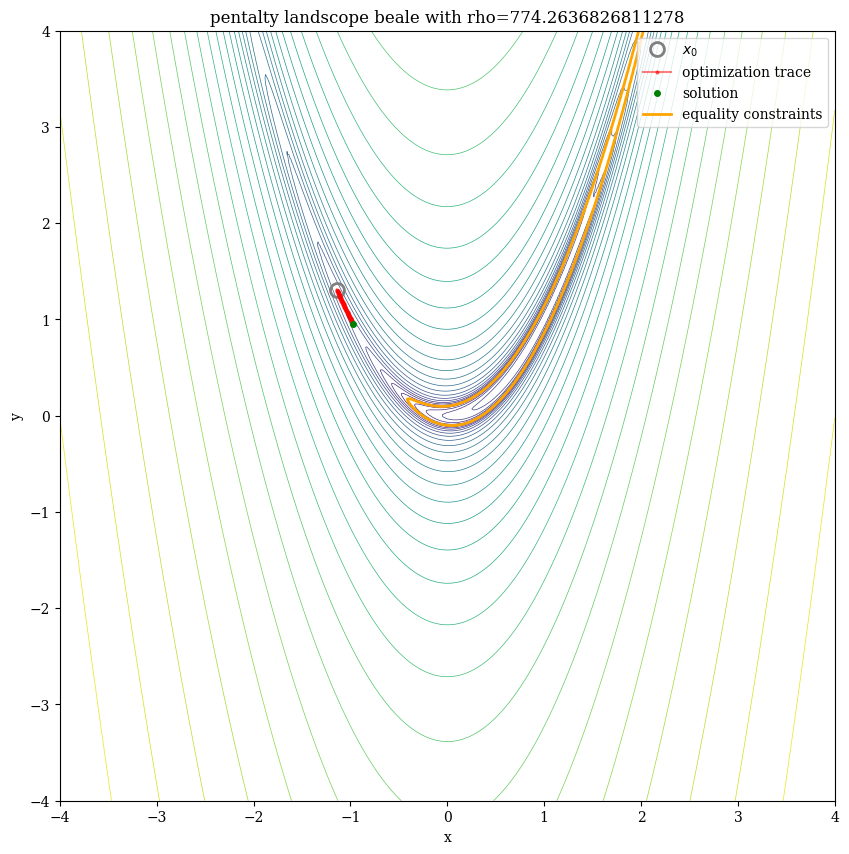

iter: 0    y: 1.251e+04  log10mu:  6.7  ratio: 0.012    dx: 0.011    reduction: 6.7    
iter: 1    y: 1.251e+04  log10mu:  6.8  ratio: 0.15     dx: 0.011    reduction: 1.2e+02
iter: 2    y: 1.238e+04  log10mu:  6.9  ratio: 0.33     dx: 0.0084   reduction: 1.8e+02
iter: 3    y: 1.22e+04   log10mu:  6.9  ratio: 0.49     dx: 0.0051   reduction: 1e+02  
iter: 4    y: 1.21e+04   log10mu:  6.9  ratio: 0.72     dx: 0.0037   reduction: 78     
iter: 5    y: 1.202e+04  log10mu:  6.9  ratio: 0.89     dx: 0.0032   reduction: 71     
iter: 6    y: 1.195e+04  log10mu:  6.8  ratio: 0.96     dx: 0.0038   reduction: 86     
iter: 7    y: 1.186e+04  log10mu:  6.6  ratio: 0.95     dx: 0.0059   reduction: 1.3e+02
iter: 8    y: 1.173e+04  log10mu:  6.2  ratio: 0.54     dx: 0.015    reduction: 2.1e+02
iter: 9    y: 1.152e+04  log10mu:  6.7  ratio: 0.045    dx: 0.011    reduction: 30     
iter: 10   y: 1.149e+04  log10mu:  6.8  ratio: 0.2      dx: 0.011    reduction: 1.6e+02
iter: 11   y: 1.133e+04  log10mu

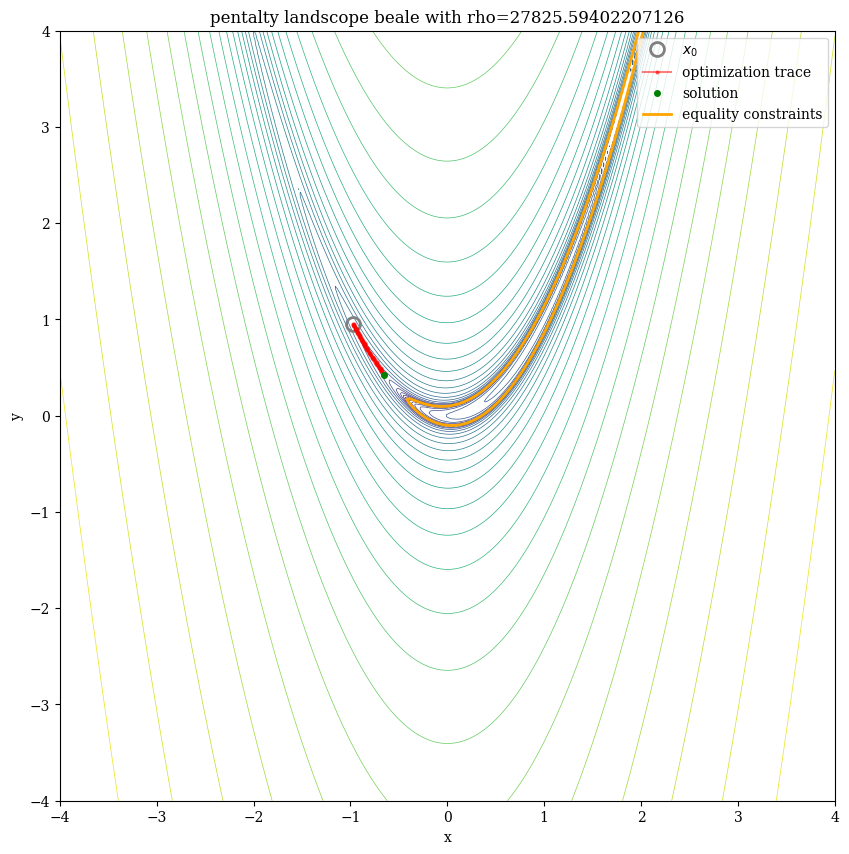

iter: 0    y: 6.509e+04  log10mu:  7.4  ratio: 0.12     dx: 0.019    reduction: 1.2e+03
iter: 1    y: 6.393e+04  log10mu:  7.6  ratio: 0.16     dx: 0.021    reduction: 3e+03  
iter: 2    y: 6.091e+04  log10mu:  7.7  ratio: 0.33     dx: 0.016    reduction: 4.7e+03
iter: 3    y: 5.62e+04   log10mu:  7.7  ratio: 0.46     dx: 0.011    reduction: 3e+03  
iter: 4    y: 5.32e+04   log10mu:  7.7  ratio: 0.65     dx: 0.0085   reduction: 2.4e+03
iter: 5    y: 5.08e+04   log10mu:  7.7  ratio: 0.83     dx: 0.0071   reduction: 2.1e+03
iter: 6    y: 4.866e+04  log10mu:  7.6  ratio: 0.92     dx: 0.0081   reduction: 2.4e+03
iter: 7    y: 4.621e+04  log10mu:  7.4  ratio: 0.9      dx: 0.012    reduction: 3.5e+03
iter: 8    y: 4.274e+04  log10mu:  7.0  ratio: 0.38     dx: 0.03     reduction: 3.6e+03
iter: 9    y: 3.918e+04  log10mu:  7.4  ratio: 0.16     dx: 0.024    reduction: 2.7e+03
iter: 10   y: 3.648e+04  log10mu:  7.5  ratio: 0.32     dx: 0.019    reduction: 4.3e+03
iter: 11   y: 3.218e+04  log10mu

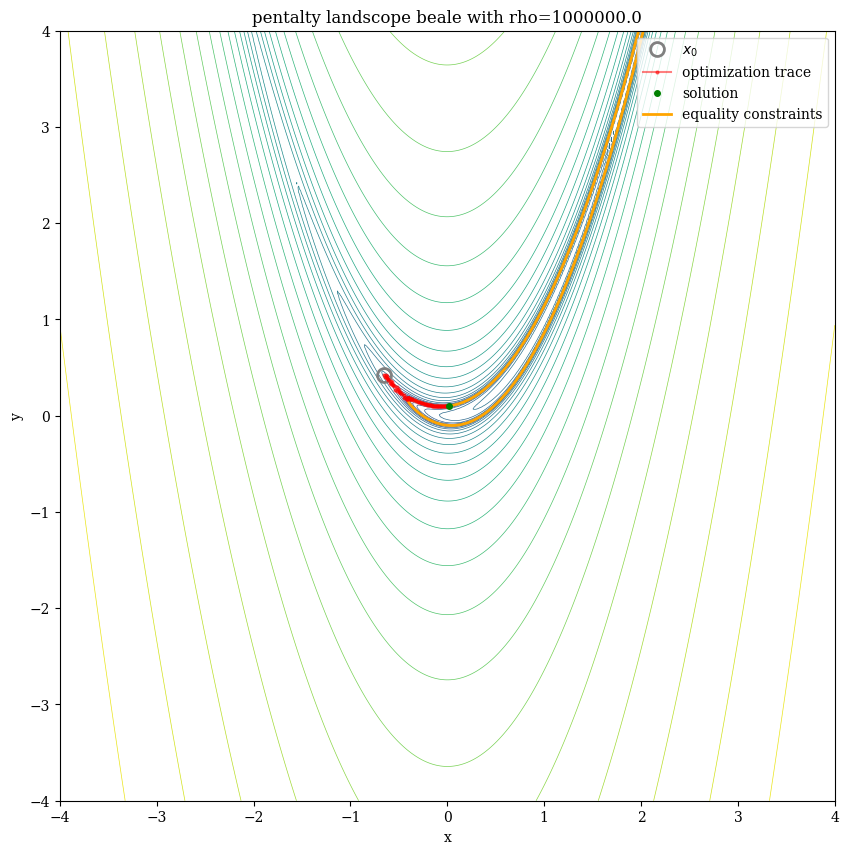

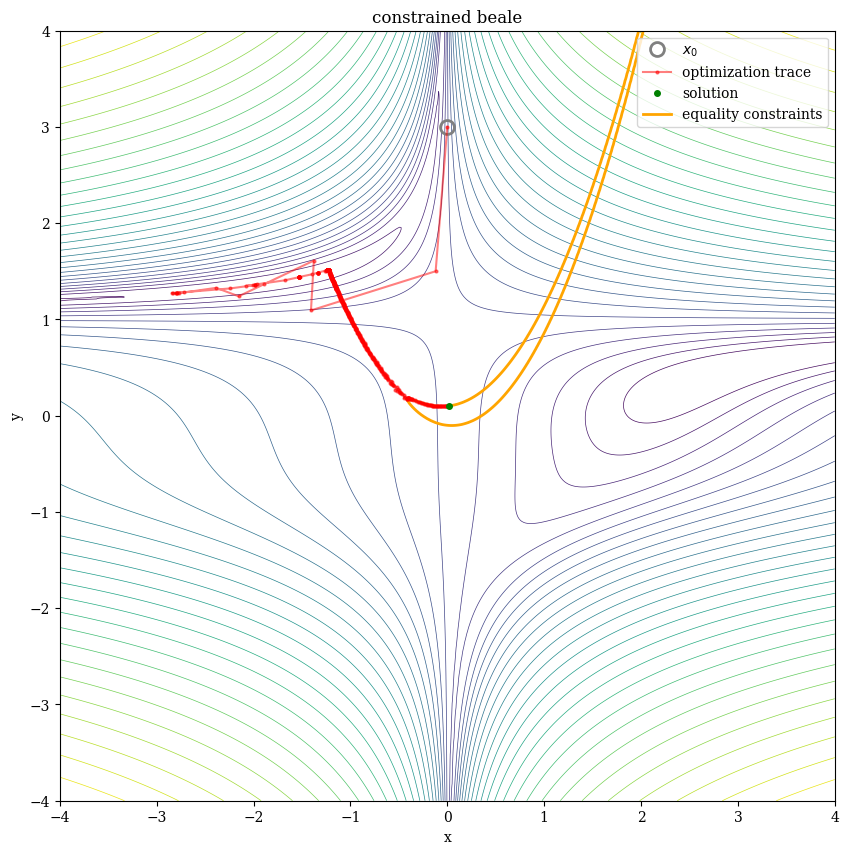

In [7]:
def rosenbrock(x):
    return np.array([1 - x[0, :], 10 * (x[1, :] - x[0, :] ** 2)])

def constraint(x):
    """등식 제약 조건: g(x) = 0.5 * ||rosenbrock(x)||^2 - 1 = 0"""
    return (rosenbrock(x)[0:1, :]**2 + rosenbrock(x)[1:2, :]**2) * 0.5 - 1

def get_p_beale_fn(rho, constraint_fn):
    """페널티가 추가된 확장 잔차 함수를 반환합니다."""
    def fn(x):
        return np.concatenate([beale(x), (rho ** 0.5) * constraint_fn(x)])
    return fn

rho_values = 10**np.linspace(-8, 6, 10)
x = np.array([0.0, 3.0])
whole_trace = [x]

for rho in rho_values:
    fn = get_p_beale_fn(rho, constraint)
    x, sub_trace = mujoco.minimize.least_squares(x, fn)
    subroutine_trace = [t.candidate.squeeze() for t in sub_trace]
    whole_trace.extend(subroutine_trace[1:])
    plot_2D(fn, f"페널티 방법 서브루틴 (rho = {rho:.1e})", plot_range=plot_range, trace=np.asarray(subroutine_trace), equality_constraints=constraint)

plot_2D(beale, "페널티 방법 전체 수렴 궤적 (Constrained Beale)", plot_range=plot_range, trace=np.asarray(whole_trace), equality_constraints=constraint)

### 4.2 원시-쌍대 방법 (Primal-Dual Method / KKT 뉴턴-랩슨)

페널티 방법(Penalty Method)은 구현이 간단하지만 치명적인 단점이 있습니다. 제약 조건을 정확히 만족시키기 위해 $\rho$를 매우 크게 키우면, 헤시안 행렬의 **조건수(Condition Number, 최대 고유값과 최소 고유값의 비율)**가 극도로 커지는 **불량 조건(Ill-conditioning)** 문제가 발생하여 수치 솔버가 수렴에 어려움을 겪습니다.

이를 극복하기 위해 라그랑주 승수(Lagrange multiplier, 쌍대 변수) $\lambda$를 도입한 라그랑지안 함수를 살펴봅시다:
$$\mathcal{L}(x, \lambda) = f(x) + \lambda^T g(x)$$

최적해 $(x^*, \lambda^*)$가 만족해야 하는 1차 필요 조건인 **KKT(Karush-Kuhn-Tucker) 조건**은 다음과 같습니다:
$$\begin{align}
\nabla_x \mathcal{L}(x, \lambda) = \nabla_x f(x) + \left[ \frac{\partial g}{\partial x}\right]^T \lambda &= 0 \nonumber\\ 
g(x) &= 0 \nonumber
\end{align}$$

이는 원시 변수 $x$와 쌍대 변수 $\lambda$를 합친 변수 $z = [x^T, \lambda^T]^T$에 대한 비선형 연립방정식 $F(z) = 0$의 근 찾기(root-finding) 문제입니다!
여기에 **뉴턴-랩슨(Newton-Raphson)** 방법을 적용하여 $x$와 $\lambda$를 동시에 업데이트하는 기법을 **원시-쌍대 방법(Primal-Dual Method)**이라고 합니다.

JAX의 자동 미분(`jax.grad`, `jax.jacobian`)을 이용해 KKT 조건에 대한 뉴턴-랩슨 스텝을 구현하고 수렴 궤적을 확인해 보겠습니다:

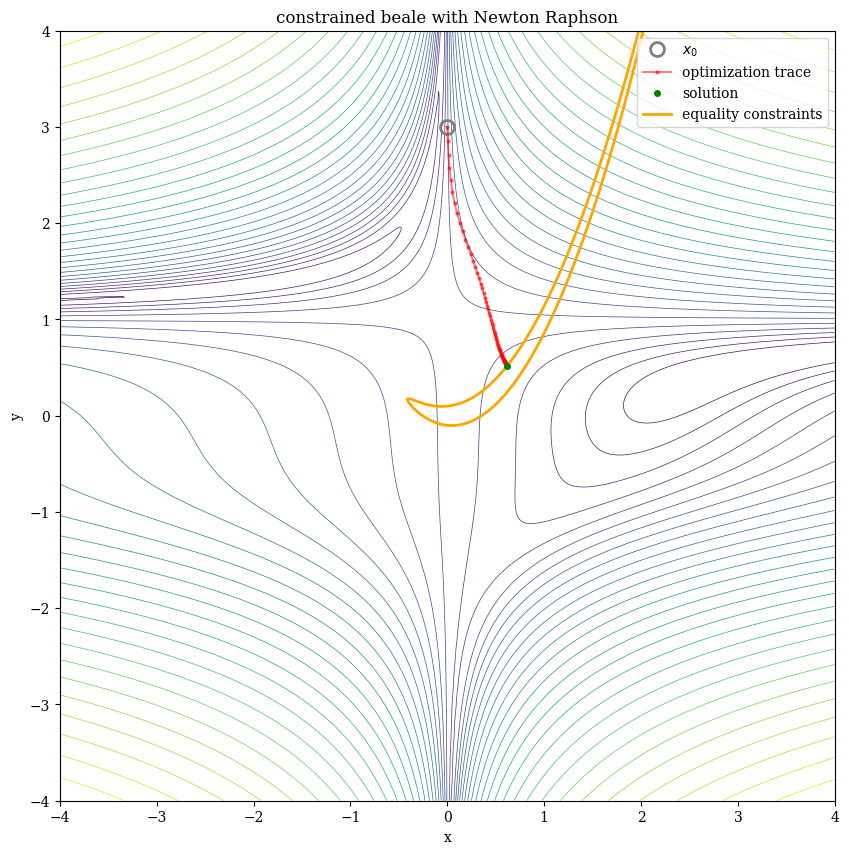

In [8]:
def constraint_jax(x):
    return jnp.sum(rosenbrock_jax(x) ** 2) / 2 - 1

def lagrangian_jax(x_lam):
    x = x_lam[:-1]
    lam = x_lam[-1]
    return jnp.sum(beale_jax(x) ** 2) / 2 + lam * constraint_jax(x) 

def KKT_jax(x_lam):
    """KKT 잔차 벡터: [dL/dx, g(x)]"""
    pLpx = jax.grad(lagrangian_jax)(x_lam)[:-1]
    return jnp.hstack([pLpx, constraint_jax(x_lam[:-1])])

@jax.jit
def newton_raphson_step(x_lam, step_size):
    residual = KKT_jax(x_lam)
    residual_jac = jax.jacobian(KKT_jax)(x_lam)
    
    dx_lam = jnp.linalg.solve(residual_jac, residual)
    return x_lam - step_size * dx_lam

x_lam = jnp.array([0.0, 3.0, 0.0])
step_size = 1e-1

primal_trace = [np.asarray(x_lam[:-1])]

for i in range(100):
    x_lam = newton_raphson_step(x_lam, step_size)
    primal_trace.append(np.asarray(x_lam[:-1]))

plot_2D(beale, "원시-쌍대 KKT 뉴턴-랩슨 (Primal-Dual Newton-Raphson)", plot_range=plot_range, trace=np.asarray(primal_trace), equality_constraints=constraint)

### 4.3 증강 라그랑지안 방법 (Augmented Lagrangian Method, ALM)

**증강 라그랑지안 방법(Augmented Lagrangian Method, ALM)**은 페널티 방법과 원시-쌍대(라그랑주 승수) 방법의 장점을 결합한 현대 로보틱스 최적화(예: AL-iLQR, trajectory optimization)의 핵심 알고리즘입니다.
$\rho$를 무한대로 키우지 않아도 라그랑주 승수 $\lambda$가 제약 조건을 정확히 만족하도록 밀어주므로, 수치적 안정성(ill-conditioning 방지)과 전역 수렴성이 매우 뛰어납니다.

**증강 라그랑지안 함수**는 라그랑지안에 2차 페널티 항을 더한 형태입니다:
$$\mathcal{L}_\rho(x, \lambda) = f(x) + \lambda^T g(x) + \frac{\rho}{2}\|g(x)\|_2^2$$

알고리즘은 다음 4단계를 반복합니다:

- **Step 1 (원시 변수 $x$ 업데이트)**:
  현재의 $\lambda_k, \rho_k$를 고정한 채 $x$에 대해 $\mathcal{L}_{\rho_k}(x, \lambda_k)$를 최소화합니다. 완전제곱식 변형을 통해 다음과 같은 표준 최소제곱법 문제로 변환하여 `mujoco.minimize.least_squares`로 쉽게 풀 수 있습니다:
  $$
  \begin{align}
  x_{k+1} &= \underset{x}{\text{argmin}} \ \mathcal{L}_{\rho_k}(x, \lambda_k) \nonumber\\
  &= \underset{x}{\text{argmin}} \ \frac{1}{2} \|r(x)\|_2^2 + \frac{\rho_k}{2} \left\|g(x) + \frac{\lambda_k}{\rho_k}\right\|_2^2 \nonumber \\
  &= \underset{x}{\text{argmin}} \ \frac{1}{2} \left\|\begin{bmatrix} r(x) \\ \sqrt{\rho_k} g(x) + \frac{\lambda_k}{\sqrt{\rho_k}} \end{bmatrix}\right\|_2^2 \nonumber
  \end{align}
  $$

- **Step 2 (쌍대 변수 / 라그랑주 승수 $\lambda$ 업데이트)**:
  $$\lambda_{k+1} = \lambda_k + \rho_k g(x_{k+1})$$

- **Step 3 (페널티 파라미터 $\rho$ 적응형 업데이트)**:
  제약 조건 위반량이 충분히(예: 이전의 $1/4$ 미만으로) 줄어들지 않았다면 $\rho$를 $\beta$배 키웁니다:
  $$
  \rho_{k+1} = \begin{cases}
  \rho_k & \text{if } \|g(x_{k+1})\| < 0.25 \|g(x_k)\| \\
  \beta \rho_k & \text{otherwise } (\beta > 1)
  \end{cases}
  $$

- **Step 4 (수렴 판정)**:
  $\|g(x_{k+1})\| < \epsilon_{\text{tol}}$이 될 때까지 반복합니다.

iter: 0    y: 1.01e+05   log10mu: -inf  ratio: 0.94     dx: 1.5      reduction: 9.5e+04
iter: 1    y: 6074       log10mu: -inf  ratio: 0.78     dx: 1.4      reduction: 4.8e+03
iter: 2    y: 1307       log10mu: -inf  ratio: 0.93     dx: 0.55     reduction: 1.2e+03
iter: 3    y: 90.33      log10mu: -inf  ratio: 0.91     dx: 0.17     reduction: 81     
iter: 4    y: 9.029      log10mu: -inf  ratio: 0.84     dx: 0.067    reduction: 7      
iter: 5    y: 1.999      log10mu:  2.6  ratio: 0.048    dx: 0.038    reduction: 0.035  
iter: 6    y: 1.964      log10mu:  2.7  ratio: 0.18     dx: 0.031    reduction: 0.1    
iter: 7    y: 1.864      log10mu:  2.8  ratio: 0.24     dx: 0.019    reduction: 0.06   
iter: 8    y: 1.803      log10mu:  2.9  ratio: 0.38     dx: 0.0086   reduction: 0.023  
iter: 9    y: 1.781      log10mu:  2.9  ratio: 0.41     dx: 0.0026   reduction: 0.0022 
iter: 10   y: 1.778      log10mu:  2.9  ratio: 0.68     dx: 0.0011   reduction: 0.0007 
iter: 11   y: 1.778      log10mu

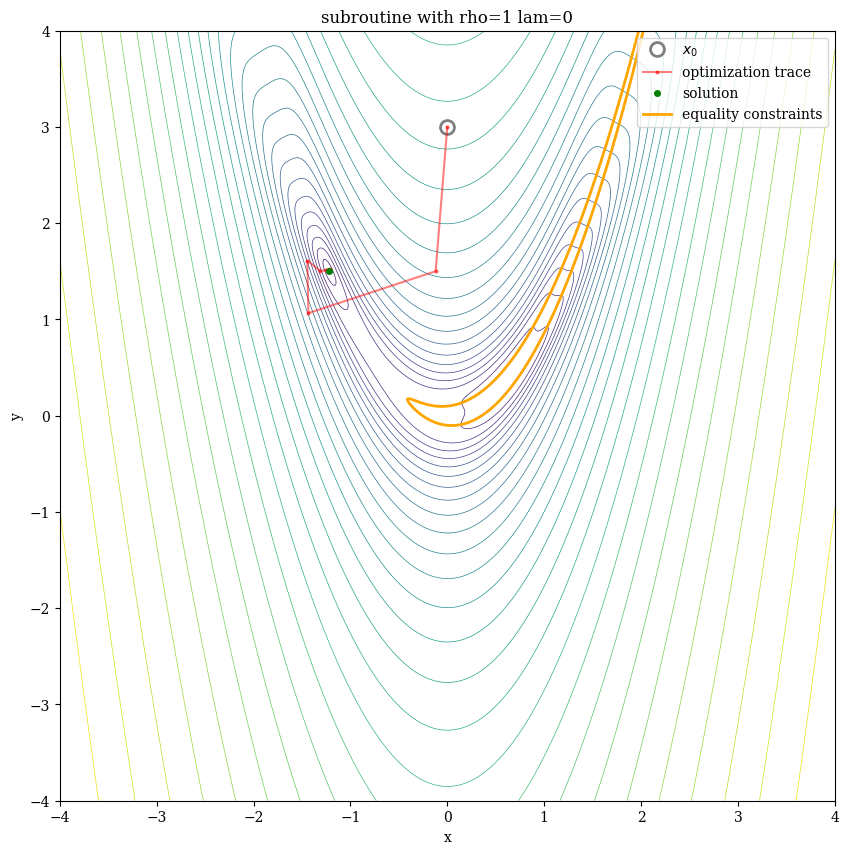

iter: 0    y: 5.036      log10mu:  2.0  ratio: 0.32     dx: 0.0069   reduction: 0.0021 
iter: 1    y: 5.034      log10mu:  3.1  ratio: 0.21     dx: 0.0033   reduction: 0.0029 
iter: 2    y: 5.031      log10mu:  3.2  ratio: 0.39     dx: 0.0017   reduction: 0.0017 
iter: 3    y: 5.03       log10mu:  3.2  ratio: 0.61     dx: 0.00058  reduction: 0.00033
iter: 4    y: 5.029      log10mu:  3.2  ratio: 0.95     dx: 0.00036  reduction: 0.0002 
iter: 5    y: 5.029      log10mu:  3.1  ratio: 1        dx: 0.00038  reduction: 0.00019
iter: 6    y: 5.029      log10mu:  2.9  ratio: 0.91     dx: 0.00061  reduction: 0.00028
iter: 7    y: 5.029      log10mu:  2.5  ratio: 0.9      dx: 0.0011   reduction: 0.00039
iter: 8    y: 5.028      log10mu:  2.8  ratio: 0.078    dx: 0.00082  reduction: 3.4e-05
iter: 9    y: 5.028      log10mu:  3.0  ratio: 0.078    dx: 0.00091  reduction: 6.5e-05
iter: 10   y: 5.028      log10mu:  3.1  ratio: 0.28     dx: 0.00074  reduction: 0.00019
iter: 11   y: 5.028      log10mu

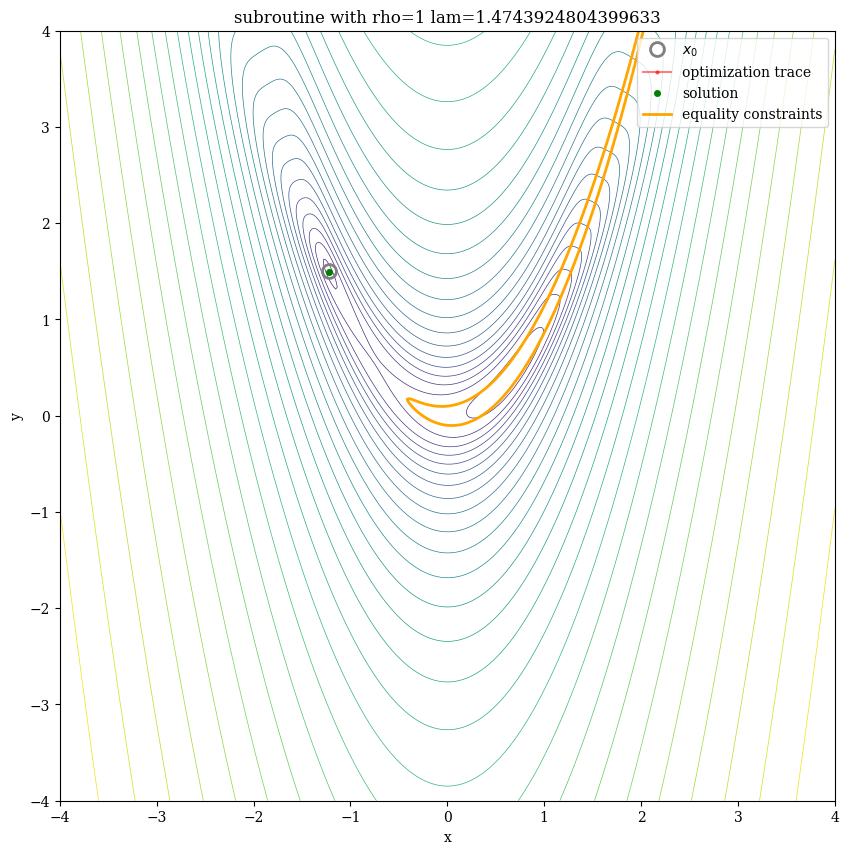

iter: 0    y: 16.14      log10mu:  1.8  ratio: 0.082    dx: 0.08     reduction: 0.057  
iter: 1    y: 16.08      log10mu:  3.8  ratio: 0.18     dx: 0.018    reduction: 0.38   
iter: 2    y: 15.7       log10mu:  3.9  ratio: 0.31     dx: 0.01     reduction: 0.25   
iter: 3    y: 15.45      log10mu:  3.9  ratio: 0.33     dx: 0.004    reduction: 0.043  
iter: 4    y: 15.4       log10mu:  3.9  ratio: 0.42     dx: 0.0018   reduction: 0.01   
iter: 5    y: 15.39      log10mu:  3.9  ratio: 0.7      dx: 0.001    reduction: 0.0056 
iter: 6    y: 15.39      log10mu:  3.9  ratio: 0.94     dx: 0.00079  reduction: 0.0046 
iter: 7    y: 15.38      log10mu:  3.8  ratio: 0.99     dx: 0.00095  reduction: 0.0056 
iter: 8    y: 15.38      log10mu:  3.6  ratio: 1        dx: 0.0015   reduction: 0.0085 
iter: 9    y: 15.37      log10mu:  3.2  ratio: 0.97     dx: 0.0035   reduction: 0.02   
iter: 10   y: 15.35      log10mu:  3.3  ratio: 0.19     dx: 0.0032   reduction: 0.004  
iter: 11   y: 15.35      log10mu

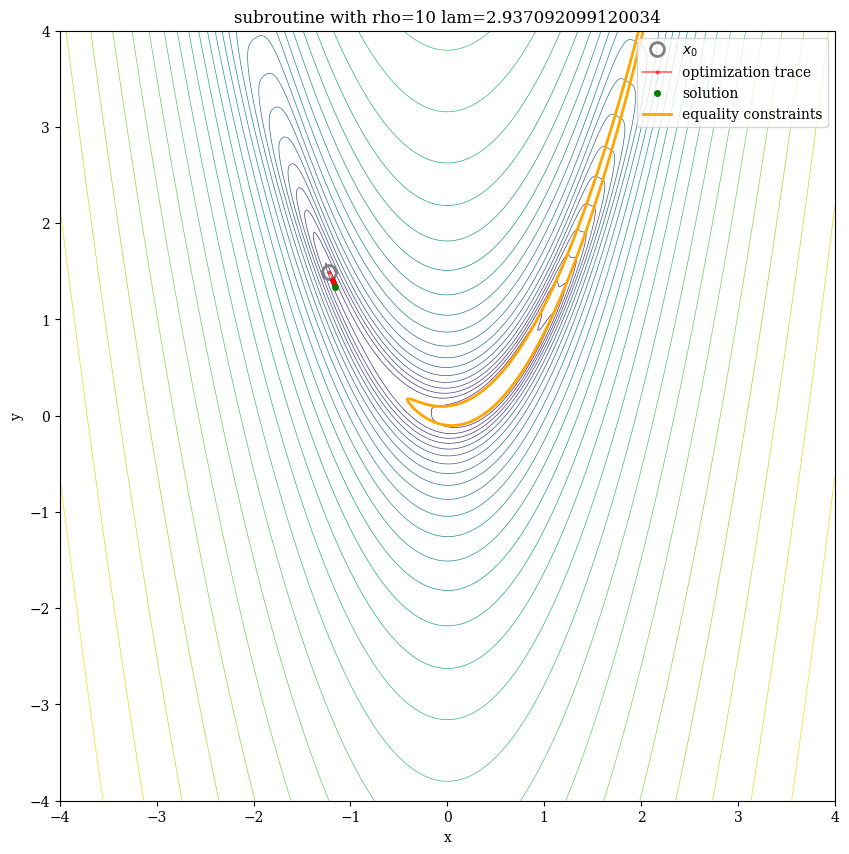

iter: 0    y: 112.4      log10mu:  0.5  ratio: 0.082    dx: 2.5      reduction: 8.9    
iter: 1    y: 103.5      log10mu:  0.6  ratio: 0.77     dx: 0.71     reduction: 78     
iter: 2    y: 25.29      log10mu:  1.0  ratio: 0.023    dx: 0.64     reduction: 0.54   
iter: 3    y: 24.75      log10mu:  1.1  ratio: 0.92     dx: 0.2      reduction: 19     
iter: 4    y: 6.017      log10mu:  1.0  ratio: 1        dx: 0.018    reduction: 1.5    
iter: 5    y: 4.501      log10mu:  1.3  ratio: 0.13     dx: 0.044    reduction: 0.0051 
iter: 6    y: 4.496      log10mu:  1.4  ratio: 0.93     dx: 0.0047   reduction: 0.0034 
iter: 7    y: 4.492      log10mu:  3.2  ratio: 0.063    dx: 5.8e-05  reduction: 3.6e-07
iter: 8    y: 4.492      log10mu:  3.3  ratio: 2        dx: 1e-05    reduction: 6.1e-07
iter: 9    y: 4.492      log10mu:  3.2  ratio: 1.6      dx: 1.3e-05  reduction: 3.9e-07
iter: 10   y: 4.492      log10mu:  3.0  ratio: 0.25     dx: 7.6e-05  reduction: 1.4e-06
iter: 11   y: 4.492      log10mu

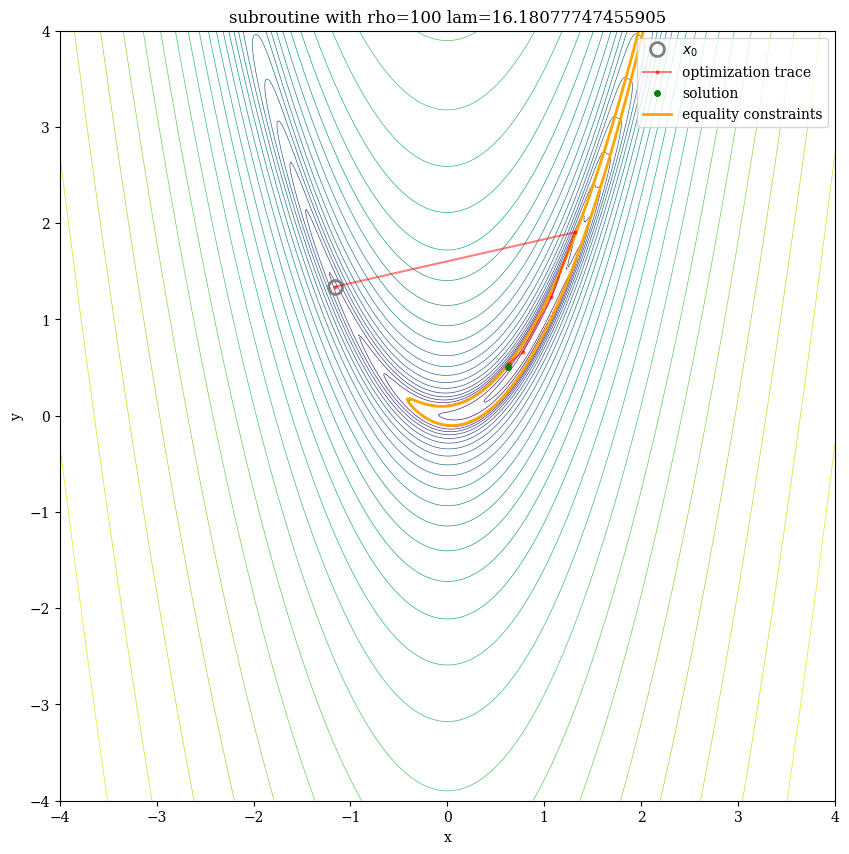

iter: 0    y: 5.879      log10mu:  0.6  ratio: 0.33     dx: 0.15     reduction: 0.48   
iter: 1    y: 5.399      log10mu:  1.0  ratio: 0.38     dx: 0.14     reduction: 0.37   
iter: 2    y: 5.033      log10mu:  1.0  ratio: 0.99     dx: 0.01     reduction: 0.5    
iter: 3    y: 4.532      log10mu:  0.9  ratio: 3.7      dx: 0.0043   reduction: 0.001  
iter: 4    y: 4.531      log10mu:  7.4  ratio: 10       dx: 1.2e-08  reduction: 3.8e-08
Terminated after 4 iterations: norm(dx) < tol. y: 4.531, Residual evals: 154
total time 35.6ms of which residual 90.7%


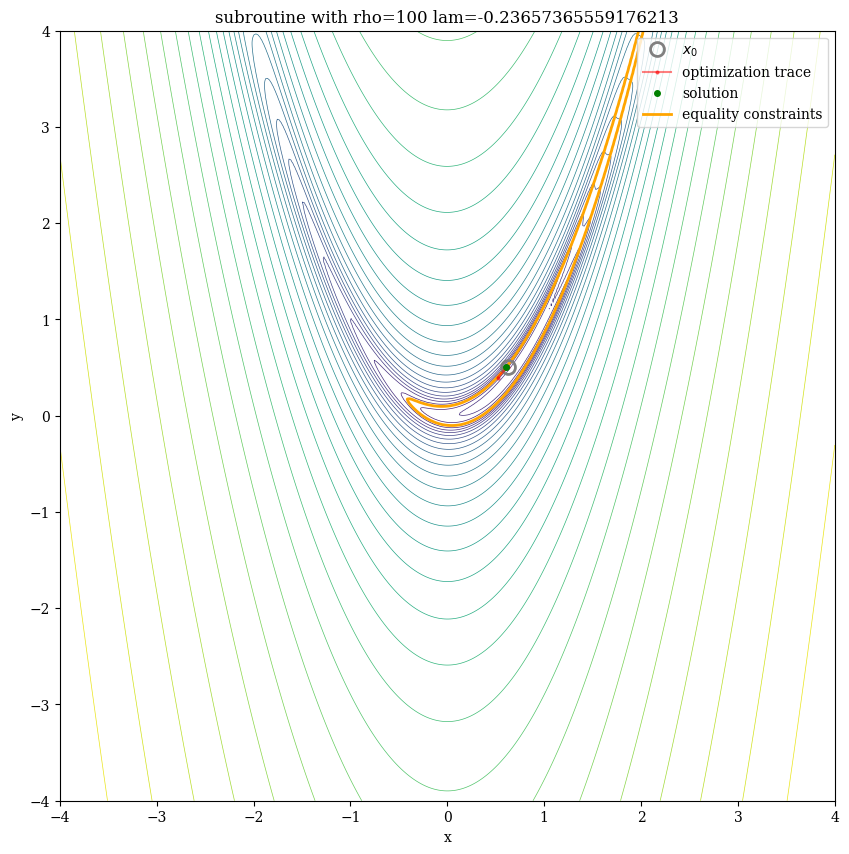

iter: 0    y: 4.531      log10mu:  4.9  ratio: 0.16     dx: 3.4e-06  reduction: 1.6e-07
Terminated after 1 iterations: insufficient reduction. y: 4.531, Residual evals: 147
total time 33.9ms of which residual 90.8%


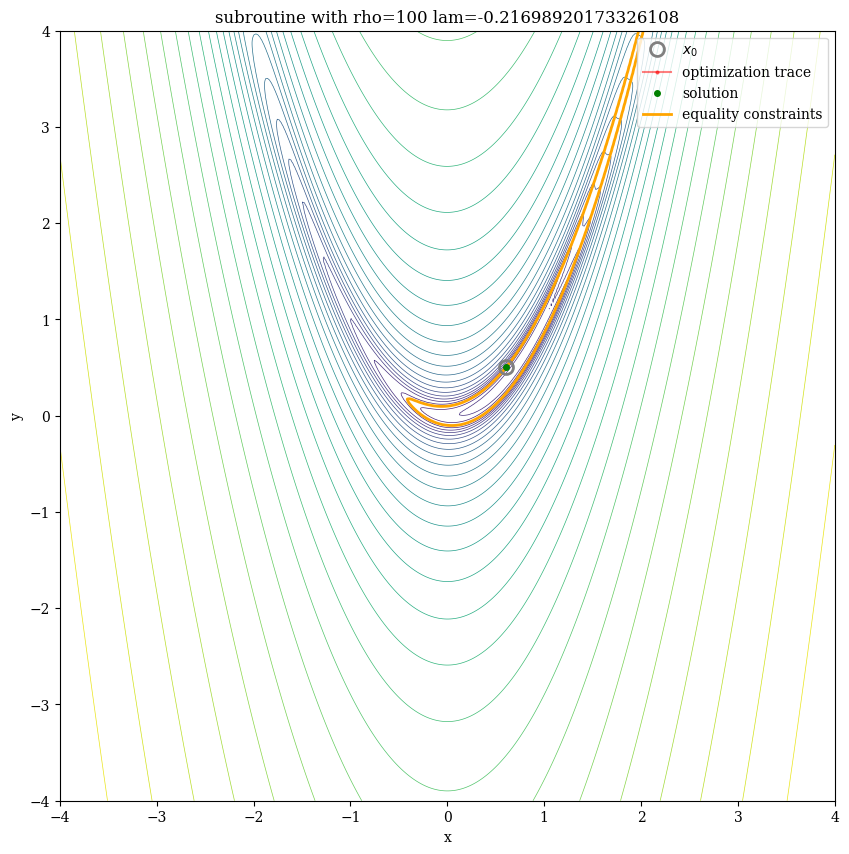

iter: 0    y: 4.531      log10mu:  3.0  ratio: 0.14     dx: 6.5e-05  reduction: 2.4e-06
iter: 1    y: 4.531      log10mu:  3.1  ratio: 0.39     dx: 0.00038  reduction: 6.9e-05
iter: 2    y: 4.531      log10mu:  3.1  ratio: 2.2      dx: 6.4e-05  reduction: 1.2e-05
iter: 3    y: 4.531      log10mu:  3.0  ratio: 0.72     dx: 0.00025  reduction: 4.4e-05
iter: 4    y: 4.531      log10mu:  3.0  ratio: 2.2      dx: 8e-05    reduction: 1.4e-05
iter: 5    y: 4.531      log10mu:  2.8  ratio: 2.5      dx: 0.00011  reduction: 1.9e-05
iter: 6    y: 4.53       log10mu:  2.4  ratio: 0.44     dx: 0.0015   reduction: 0.00025
iter: 7    y: 4.53       log10mu:  4.8  ratio: 0.24     dx: 1.9e-06  reduction: 1.9e-07
iter: 8    y: 4.53       log10mu:  7.3  ratio: 30       dx: 5.9e-09  reduction: 2.1e-08
Terminated after 8 iterations: norm(dx) < tol. y: 4.53, Residual evals: 167
total time 43.0ms of which residual 90.5%


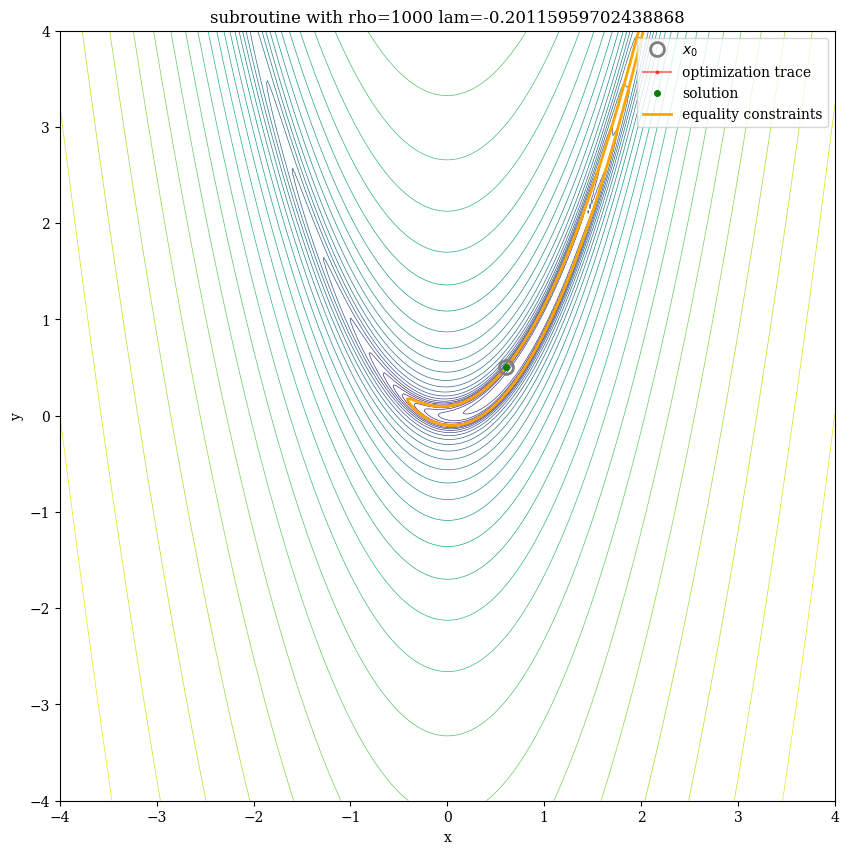

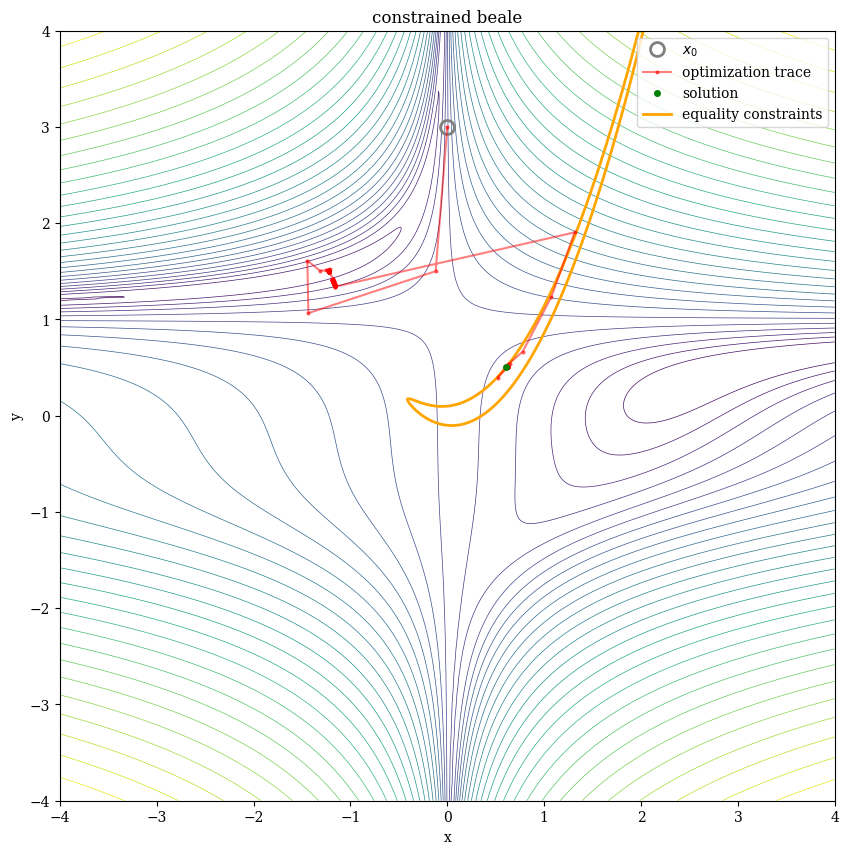

In [9]:
x0 = np.array([0.0, 3.0])
lam0 = 0.0

def augmented_lagrangian(x0, lam0, obj_fn, constraint_fn, rho=1, beta=10, threshold=1e-5, max_it=int(100), is_show_subroutine=True):
    """증강 라그랑지안(Augmented Lagrangian) 알고리즘 구현"""
    def get_aug_fn(rho, lam):
        def fn(x):
            return np.concatenate([obj_fn(x), (rho ** 0.5) * constraint_fn(x) + lam / (rho ** 0.5)])
        return fn
    
    x = x0.copy()
    lam = lam0
    g = constraint_fn(x[:, None]).squeeze()

    primal_trace = [x]
    dual_trace = [lam]

    for i in range(max_it):
        # Step 1: 고정된 (rho, lam) 하에서 x에 대한 최소제곱법 풀이
        fn = get_aug_fn(rho, lam)
        x, sub_trace = mujoco.minimize.least_squares(
            x, fn,
            verbose=int(is_show_subroutine) * mujoco.minimize.Verbosity(mujoco.minimize.Verbosity.ITER).value
        )
        subroutine_trace = [t.candidate.squeeze() for t in sub_trace]
        primal_trace.extend(subroutine_trace[1:])
        
        # 서브루틴 수렴 과정 시각화
        if is_show_subroutine:
            plot_2D(fn, f"ALM 서브루틴 (rho={rho}, lam={lam:.3f})", plot_range=plot_range, trace=np.asarray(subroutine_trace), equality_constraints=constraint_fn)
        
        # Step 2: 라그랑주 승수(dual variable) 업데이트
        g_next = constraint_fn(x[:, None]).squeeze()
        lam = lam + rho * g_next.squeeze()
        dual_trace.append(lam)

        # Step 3: 제약 위반 감소폭이 부족할 때만 페널티(rho) 증가
        if abs(g_next) >= abs(g) / 4:
            rho = beta * rho

        g = g_next
        # Step 4: 수렴 확인
        if abs(g) < threshold:
            break

    return x, primal_trace, dual_trace

x, primal_trace, dual_trace = augmented_lagrangian(x0, lam0, beale, constraint)

plot_2D(beale, "증강 라그랑지안 전체 수렴 궤적 (Augmented Lagrangian)", plot_range=plot_range, trace=np.asarray(primal_trace), equality_constraints=constraint)

### 초기값에 따른 국소 최적해(Local Minimum) 민감도 확인
비볼록 제약 최적화 문제에서는 초기 추정값($x_0$)에 따라 서로 다른 국소 최적해로 수렴할 수 있습니다.
초기값을 `[0.0, 3.0]`에서 `[-0.01, 3.0]`으로 아주 약간만 이동시켰을 때 왼쪽 가지를 따라 다른 수렴 해로 도달하는 모습을 확인해 보세요:

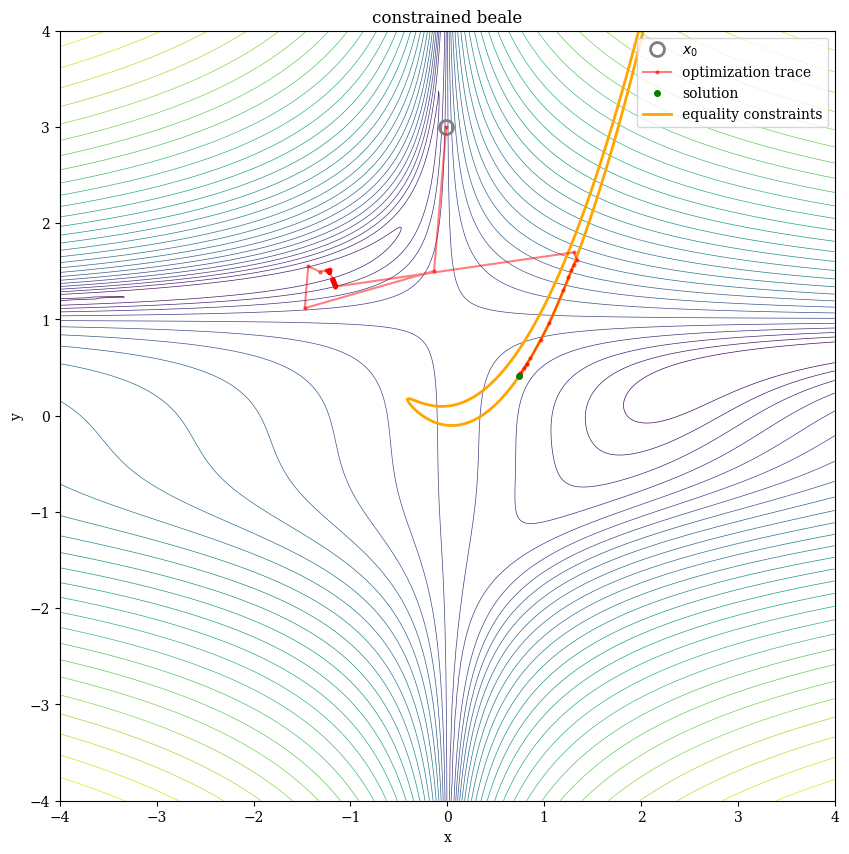

In [10]:
x0 = np.array([-0.01, 3.0])
lam0 = 0.0

x, primal_trace, dual_trace = augmented_lagrangian(x0, lam0, beale, constraint, is_show_subroutine=False)
plot_2D(beale, "초기값 섭동 시 수렴 궤적 (x0 = [-0.01, 3.0])", plot_range=plot_range, trace=np.asarray(primal_trace), equality_constraints=constraint)